# Weeks 1: Data Collection & Ingestion

## Paths

In [1]:
""" AgroRestore AI - central configuration (Weeks 1: Phases 2-4)
=============================================================
Edit this file only. Every other script/notebook reads from here. """

from pathlib import Path
 
# Paths

ROOT = Path.cwd()
DATA_RAW = ROOT / "data" / "DATA_RAW"              # Phase 2 output (GeoTIFFs from GEE, OSM files)
DATA_PROCESSED = ROOT / "data" / "DATA_PROCESSED"  # Phase 3 output (stack, GeoDataFrame)
DATA_LABELS = ROOT / "data" / "DATA_LABELS"        # optional: TREES ground-truth labels (Week 2)
FIGURES = ROOT / "reports" / "FIGURES"
for _p in (DATA_RAW, DATA_PROCESSED, DATA_LABELS, FIGURES):
    _p.mkdir(parents=True, exist_ok=True)

# Create folders if they don't exist yet
for folder in [DATA_RAW, DATA_PROCESSED, DATA_LABELS]:
    folder.mkdir(parents=True, exist_ok=True)
    print(f"✅ Created: {folder}")

✅ Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_RAW
✅ Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED
✅ Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_LABELS


# Google Earth Engine

In [2]:
# Google Earth Engine

GEE_PROJECT = "agrorestore-ai"   # <-- REQUIRED: your Google Cloud project registered for Earth Engine
 
# "local" : download GeoTIFFs straight to DATA_RAW with geemap (simple; fine for AOIs up to a few 100 km wide)
# "drive" : start ee.batch export tasks to Google Drive (robust for big AOIs); download the files into DATA_RAW yourself
EXPORT_MODE = "local"
DRIVE_FOLDER = "agrorestore_raw"

In [3]:
import ee
import geemap

ee.Authenticate()
# Initialize Earth Engine with your specific Cloud Project
ee.Initialize(project=GEE_PROJECT)

print(f"Successfully authenticated and initialized Earth Engine for project: {GEE_PROJECT}")

ModuleNotFoundError: No module named 'ee'

# Common analysis grid

In [51]:
# Common analysis grid
# --------------------------------------------------------------------------
TARGET_SCALE = 250        # metres. 250 m = native SoilGrids & MODIS NDVI; keeps the MVP light.
TARGET_CRS = "auto"       # "auto" -> UTM zone of the AOI centroid, or give e.g. "EPSG:32630"

# Time windows

In [52]:
# Time windows
# --------------------------------------------------------------------------
CLIMATE_YEARS = (2006, 2025)     # CHIRPS / ERA5-Land record used for rainfall reliability
NDVI_YEARS = (2006, 2025)        # MODIS MOD13Q1 starts Feb 2000
FIRE_LONG_YEARS = (2006, 2025)   # 20 full years -> fire frequency index
FIRE_RECENT_YEARS = (2006, 2025)


# Dataset choices

In [53]:
# Dataset choices
# --------------------------------------------------------------------------
DEM_SOURCE = "srtm"              # "srtm" (USGS/SRTMGL1_003) | "copernicus" (COPERNICUS/DEM/GLO30)
WORLDCOVER_COLLECTION = "ESA/WorldCover/v200"   # 2021 map
GHSL_BUILT_EPOCH = 2020
GHSL_BUILT_THRESHOLD_M2 = 500    # built-up m2 per 100 m cell (of 10,000) to count as "settlement"
FIRMS_MIN_CONFIDENCE = 50
 
# OSM (roads + village points) - used for the accessibility proxy in Phase 3
USE_OSM = True
OSM_HIGHWAY_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary",
                       "unclassified", "residential", "track"]   # 'track' matters a lot in the Sahel
OSM_PLACE_CLASSES = ["city", "town", "village", "hamlet"]

# Phase 3 thresholds

In [54]:
# Phase 3 thresholds
# --------------------------------------------------------------------------
URBAN_BUILT_FRACTION = 0.25      # WorldCover built-up fraction in a 250 m cell -> urban exclusion
WATER_FRACTION = 0.50            # permanent water fraction -> water exclusion
MAX_GAP_FILL_PIXELS = 4          # nearest-neighbour gap filling radius (soil/climate layers only)
MIN_NDVI_YEARS_VALID = 15        # min valid seasons per pixel for resilience metrics
DIP_THRESHOLD_Z = -0.5           # NDVI anomaly (z-score) that counts as a "dip" to recover from
BLOCK_SIZE_M = 10_000            # spatial block size (for spatial CV in Week 2)
SAVE_GPKG = False                # also write a GeoPackage for QGIS (slow for >1M pixels)
RANDOM_STATE = 42

# Area of Interest (AOI) Definition

In [55]:
import ee
import geemap
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.ops import unary_union
from pathlib import Path
import warnings
import pyogrio
warnings.filterwarnings('ignore')


# --------------------------------------------------------------------------
# Area of Interest (AOI) Definition
# --------------------------------------------------------------------------
# Format: [min_longitude, min_latitude, max_longitude, max_latitude]
AOI = {
    "mode": "bbox",
    "bbox": [-2.0, 12.5, 0.0, 14.0]  # Central-northern Burkina Faso
}
 
# 1. Convert to Earth Engine Geometry
if AOI["mode"] == "bbox":
    aoi_ee = ee.Geometry.BBox(*AOI["bbox"])
else:
    raise ValueError("Only 'bbox' mode is supported for this MVP.")

# 2. Convert to GeoPandas DataFrame for local spatial operations (e.g., OSM downloads)
aoi_gdf = geemap.ee_to_gdf(ee.FeatureCollection([ee.Feature(aoi_ee)]))

# 3. Verify and print
print(f"Area of Interest defined successfully.")
print(f"📍 Spatial Bounds (minx, miny, maxx, maxy): {aoi_gdf.total_bounds}")

Area of Interest defined successfully.
📍 Spatial Bounds (minx, miny, maxx, maxy): [-2.  12.5  0.  14. ]


# Feature engineering function

In [56]:
from datetime import datetime, timezone

def last_full_year(col_id):
    """Last calendar year that the collection fully covers."""
    ms = ee.ImageCollection(col_id).aggregate_max("system:time_start").getInfo()
    d = datetime.fromtimestamp(ms / 1000, tz=timezone.utc)
    return d.year if (d.month, d.day) >= (12, 1) else d.year - 1

def get_features_image(aoi):
    """Computes and stacks all engineered features (sampled later at TARGET_SCALE)."""

    # ---- safe year windows (end is exclusive: next year's Jan 1) ----
    clim_end = min(CLIMATE_YEARS[1], last_full_year("UCSB-CHG/CHIRPS/DAILY"),
                   last_full_year("IDAHO_EPSCOR/TERRACLIMATE"))
    ndvi_end = min(NDVI_YEARS[1], last_full_year("MODIS/061/MOD13Q1"))
    fire_end = min(FIRE_LONG_YEARS[1], last_full_year("MODIS/061/MCD64A1"))
    print(f"Using climate to {clim_end}, NDVI to {ndvi_end}, fire to {fire_end}")

    # 1. Climate
    precipitation = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
        .filterDate(f"{CLIMATE_YEARS[0]}-01-01", f"{clim_end + 1}-01-01")
        .select("precipitation").mean()
        .rename("precipitation_mean"))

    tc = (ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
        .filterDate(f"{CLIMATE_YEARS[0]}-01-01", f"{clim_end + 1}-01-01")
        .select(["tmmn", "tmmx"]))
    tmin = tc.select("tmmn").mean().multiply(0.1).rename("tmin")   # TerraClimate scale 0.1 -> deg C
    tmax = tc.select("tmmx").mean().multiply(0.1).rename("tmax")
    tmean = tmin.add(tmax).divide(2).rename("tmean")

    soil_moisture = (ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
        .select("soil")
        .filterDate("1991-01-01", f"{clim_end + 1}-01-01")
        .filter(ee.Filter.calendarRange(7, 10, "month"))
        .mean().multiply(0.1).rename("soil_moisture"))             # mm

    # 2. Soil: iSDAsoil
    soil_soc = (ee.Image("ISDASOIL/Africa/v1/carbon_organic").select("mean_0_20")
                .divide(10).exp().subtract(1).rename("soc"))       # log-scaled; verify on catalog page
    soil_ph = ee.Image("ISDASOIL/Africa/v1/ph").select("mean_0_20").divide(10).rename("ph")

    # 3. Topography
    dem = ee.Image("USGS/SRTMGL1_003")
    slope = ee.Terrain.slope(dem).rename("slope")
    # aspect = ee.Terrain.aspect(dem).rename("aspect")
    elevation = dem.select("elevation").rename("elevation")

    # 4. Land cover
    wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
    built_up = wc.eq(50).rename("built_up")
    water = wc.eq(80).rename("water")

    # 5. Protected zone
    region = ee.Geometry.BBox(*aoi.total_bounds)
    wdpa = (ee.FeatureCollection("WCMC/WDPA/current/polygons")
            .filterBounds(region)
            .filter(ee.Filter.inList("STATUS", ["Designated", "Inscribed", "Established", "Adopted"])))
    protected = ee.Image.constant(0).paint(wdpa, 1).rename("protected")   # 1 inside a protected area, else 0
        

    # 6. Fire: fraction of years burned (one 0/1 flag per year, skip years with no data)
    burn = ee.ImageCollection("MODIS/061/MCD64A1").select("BurnDate")
    flags = []
    for y in range(FIRE_LONG_YEARS[0], fire_end + 1):
        yr = burn.filterDate(f"{y}-01-01", f"{y + 1}-01-01")
        if yr.size().getInfo() > 0:
            flags.append(yr.max().gt(0).unmask(0).rename("burned"))
    print(f"Fire years used: {len(flags)}")
    fire_freq = ee.ImageCollection.fromImages(flags).mean().rename("fire_freq")

    # 7. Vegetation
    ndvi_col = (ee.ImageCollection("MODIS/061/MOD13Q1")
        .filterDate(f"{NDVI_YEARS[0]}-01-01", f"{ndvi_end + 1}-01-01")
        .select("NDVI").map(lambda img: img.multiply(0.0001)))
    ndvi_mean = ndvi_col.mean().rename("ndvi_mean")
    ndvi_std = ndvi_col.reduce(ee.Reducer.stdDev()).rename("ndvi_std")
    ndvi_resilience = ndvi_mean.divide(ndvi_std.add(0.01)).rename("ndvi_resilience")

    # --- Outcome: NDVI trend (NDVI change per year, linear fit on annual mean NDVI) ---
    def annual_ndvi(y):
        start = ee.Date.fromYMD(y, 1, 1)
        nd = (ee.ImageCollection("MODIS/061/MOD13Q1").select("NDVI")
              .filterDate(start, start.advance(1, "year"))
              .mean().multiply(0.0001).rename("ndvi"))
        return ee.Image.cat([ee.Image.constant(y).float().rename("year"), nd])

    ndvi_trend = (ee.ImageCollection.fromImages(
                      [annual_ndvi(y) for y in range(NDVI_YEARS[0], ndvi_end + 1)])
                  .reduce(ee.Reducer.linearFit())
                  .select("scale").rename("ndvi_trend"))
    
    # Stack all layers
    return ee.Image.cat([
        precipitation, tmean, tmin, tmax, soil_soc, soil_ph, soil_moisture, protected,ndvi_trend,
        elevation, slope, built_up, water, fire_freq, ndvi_mean, ndvi_std, ndvi_resilience
    ])


print("✅ Feature engineering function defined successfully.")

✅ Feature engineering function defined successfully.


# Data Sampling points from Earth Engine

In [57]:
print("Sampling points from Earth Engine (this may take 1-2 minutes)...")
num_points = 10000

# Create dummy image to sample random points
dummy = ee.Image(1).rename('dummy')
random_points = dummy.sample(
    region=aoi_ee, scale=TARGET_SCALE, numPixels=num_points, 
    seed=RANDOM_STATE, geometries=True
)

# Extract features
features_image = get_features_image(aoi_gdf)
sampled_fc = features_image.sampleRegions(
    collection=random_points, scale=TARGET_SCALE, geometries=True
)

# Convert to GeoPandas
print(" Converting to GeoPandas DataFrame...")
gdf = geemap.ee_to_gdf(sampled_fc)
print(f"Successfully sampled {len(gdf)} points.")

# --- LOCAL FEATURE ENGINEERING (Accessibility) ---
from shapely.geometry import box
from shapely.ops import unary_union
import pyogrio


features_image = get_features_image(aoi_gdf)
sampled_fc = features_image.sampleRegions(
    collection=random_points, scale=TARGET_SCALE, geometries=True)

# Convert to GeoPandas
print(" Converting to GeoPandas DataFrame...")
gdf = geemap.ee_to_gdf(sampled_fc)
print(f"Successfully sampled {len(gdf)} points.")

PBF_PATH = r"C:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\PROJECT_DATA_SCIENCE\africa-261009.osm.pbf"
minx, miny, maxx, maxy = aoi_gdf.total_bounds
ROAD_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary",
                    "unclassified", "residential", "track"]
PLACE_CLASSES = ["village", "hamlet", "town", "city"]
    
try:
    lines = gpd.read_file(PBF_PATH, layer="lines", bbox=(minx, miny, maxx, maxy))
    points = gpd.read_file(PBF_PATH, layer="points", bbox=(minx, miny, maxx, maxy))
    
    roads_gdf = lines[lines["highway"].isin(ROAD_CLASSES)][["highway", "geometry"]]
    settlements_gdf = points[points["other_tags"].fillna("").str.contains(
            "|".join(f'"place"=>"{p}"' for p in PLACE_CLASSES))][["geometry"]]
    
    utm = gdf.estimate_utm_crs()
    gdf_utm = gdf.to_crs(utm)
    gdf["dist_to_road_m"] = (gdf_utm.geometry.distance(unary_union(roads_gdf.to_crs(utm).geometry)).values
                                 if not roads_gdf.empty else np.nan)
    gdf["dist_to_settlement_m"] = (gdf_utm.geometry.distance(unary_union(settlements_gdf.to_crs(utm).geometry)).values
                                       if not settlements_gdf.empty else np.nan)
    print(f"OSM done. Road segments: {len(roads_gdf)}, settlements: {len(settlements_gdf)}")
except Exception as e:
        print(f"OSM failed. Filling with NaN. Error: {e}")
        gdf["dist_to_road_m"] = np.nan
        gdf["dist_to_settlement_m"] = np.nan
    
# --- EXCLUSION MASKS ---
initial_count = len(gdf)
gdf = gdf[(gdf['built_up'] == 0) & (gdf['water'] == 0)].copy()
print(f"Exclusion masks applied. Removed {initial_count - len(gdf)} urban/water points.")

# --- DATA QUALITY ---
critical_cols = ['soc', 'ph', 'fire_freq', 'ndvi_mean', 'slope']
gdf = gdf.dropna(subset=critical_cols).reset_index(drop=True)
print(f"Data quality validated. Final clean dataset: {len(gdf)} points.")

# --- PROXY TARGET FOR EDA ---
gdf['proxy_target'] = np.where(
    (gdf['fire_freq'] < 0.2) & (gdf['ndvi_mean'] > 0.4) & (gdf['slope'] < 15), 1, 0
)

# Save Deliverable
gdf.to_file(DATA_PROCESSED / "week1_features_sample.gpkg", driver="GPKG")
gdf.to_csv(DATA_PROCESSED / "week1_features_sample.csv", index=False)
print(f" Saved clean GeoDataFrame to: {DATA_PROCESSED}")

Sampling points from Earth Engine (this may take 1-2 minutes)...
Using climate to 2024, NDVI to 2025, fire to 2025
Fire years used: 20
 Converting to GeoPandas DataFrame...
Successfully sampled 9977 points.
Using climate to 2024, NDVI to 2025, fire to 2025
Fire years used: 20
 Converting to GeoPandas DataFrame...
Successfully sampled 9977 points.
OSM done. Road segments: 18976, settlements: 0
Exclusion masks applied. Removed 74 urban/water points.
Data quality validated. Final clean dataset: 9903 points.
 Saved clean GeoDataFrame to: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED


# EDA

AOI area: 35,986 km²


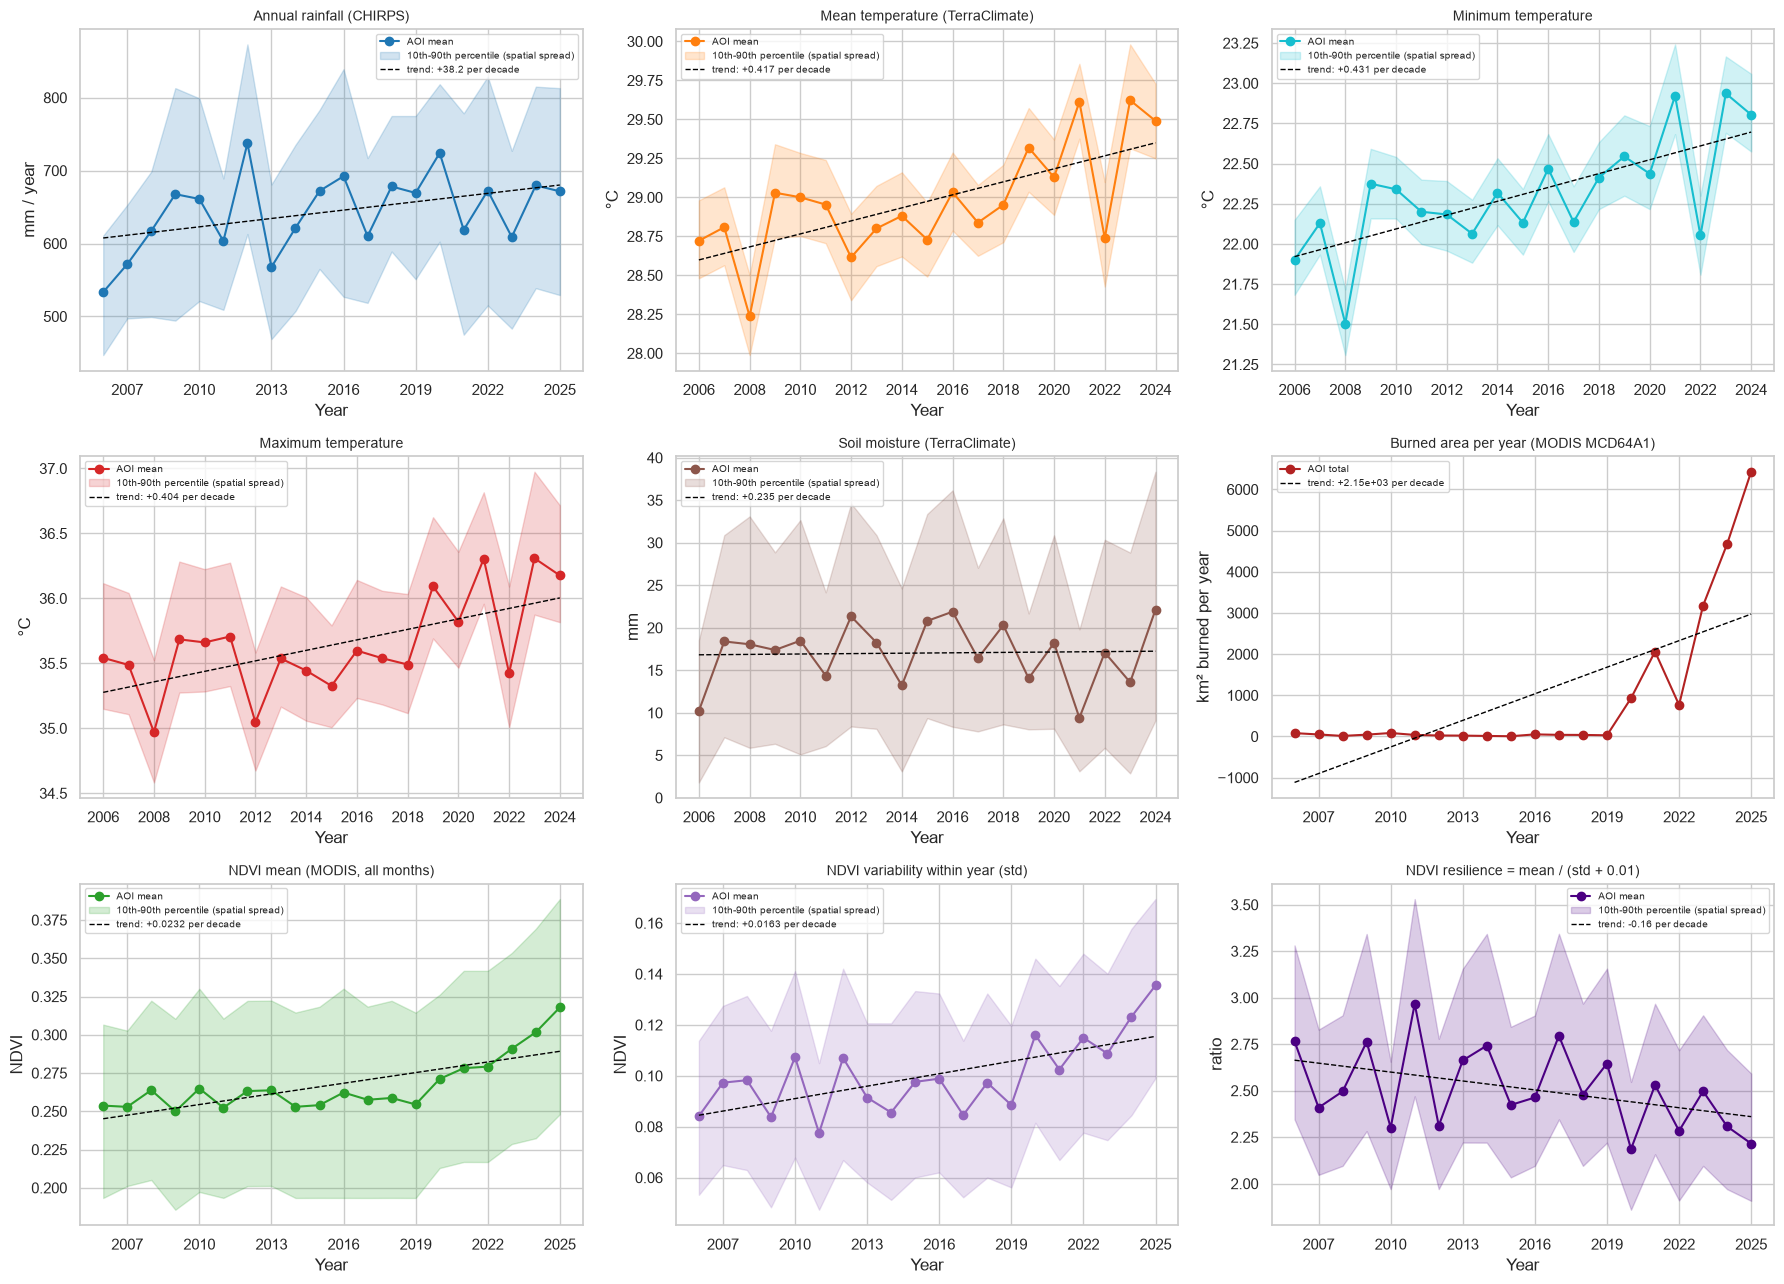

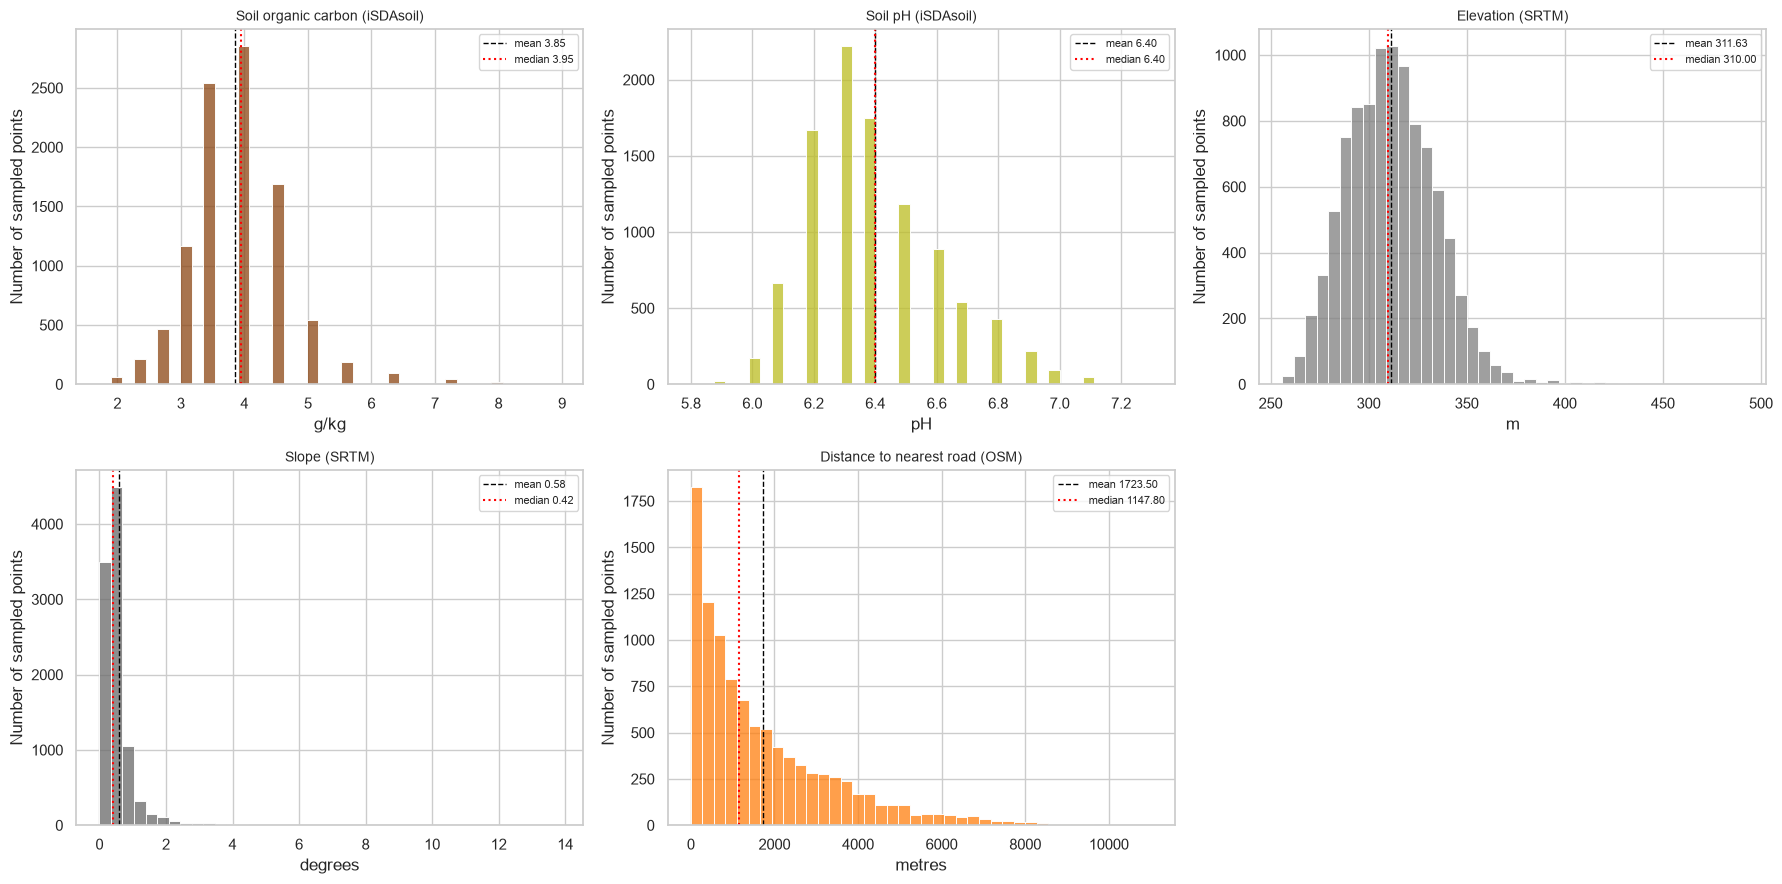

STATIC FEATURES (sampled points)
           soc       ph  elevation    slope  dist_to_road_m
count  9903.00  9903.00    9903.00  9903.00         9903.00
mean      3.85     6.40     311.63     0.58         1723.50
std       0.79     0.22      22.95     0.80         1724.42
min       1.72     5.80     256.00     0.00            0.32
25%       3.48     6.20     295.00     0.26          412.44
50%       3.95     6.40     310.00     0.42         1147.80
75%       4.47     6.50     326.00     0.61         2532.71
max       8.97     7.30     491.00    13.86        11029.52

YEARLY FEATURES (AOI mean per year, 2006-2025; burned_area in km² burned)
       precipitation  tmean   tmin   tmax  soil_moisture  burned_area   ndvi  ndvi_std  ndvi_resilience
count          20.00  19.00  19.00  19.00          19.00        20.00  20.00     20.00            20.00
mean          643.90  28.97  22.31  35.64          17.03       928.73   0.27      0.10             2.51
std            52.80   0.35   0.35   0.3

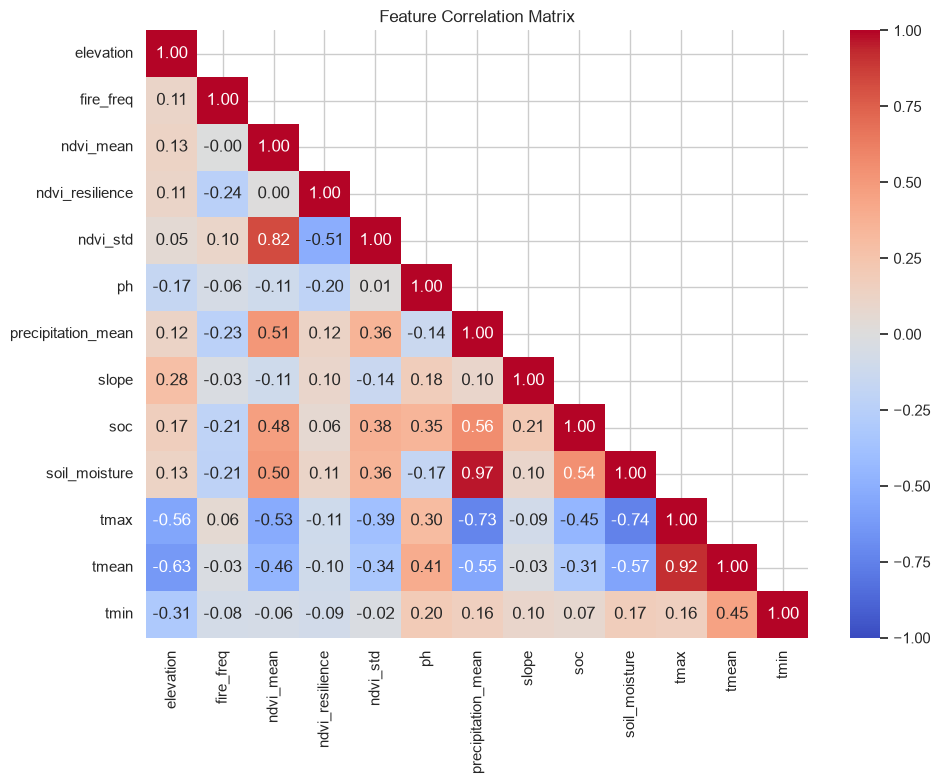


Pairs with |rho| >= 0.8:
    feature_1          feature_2  rho
soil_moisture precipitation_mean 0.97
        tmean               tmax 0.92
     ndvi_std          ndvi_mean 0.82


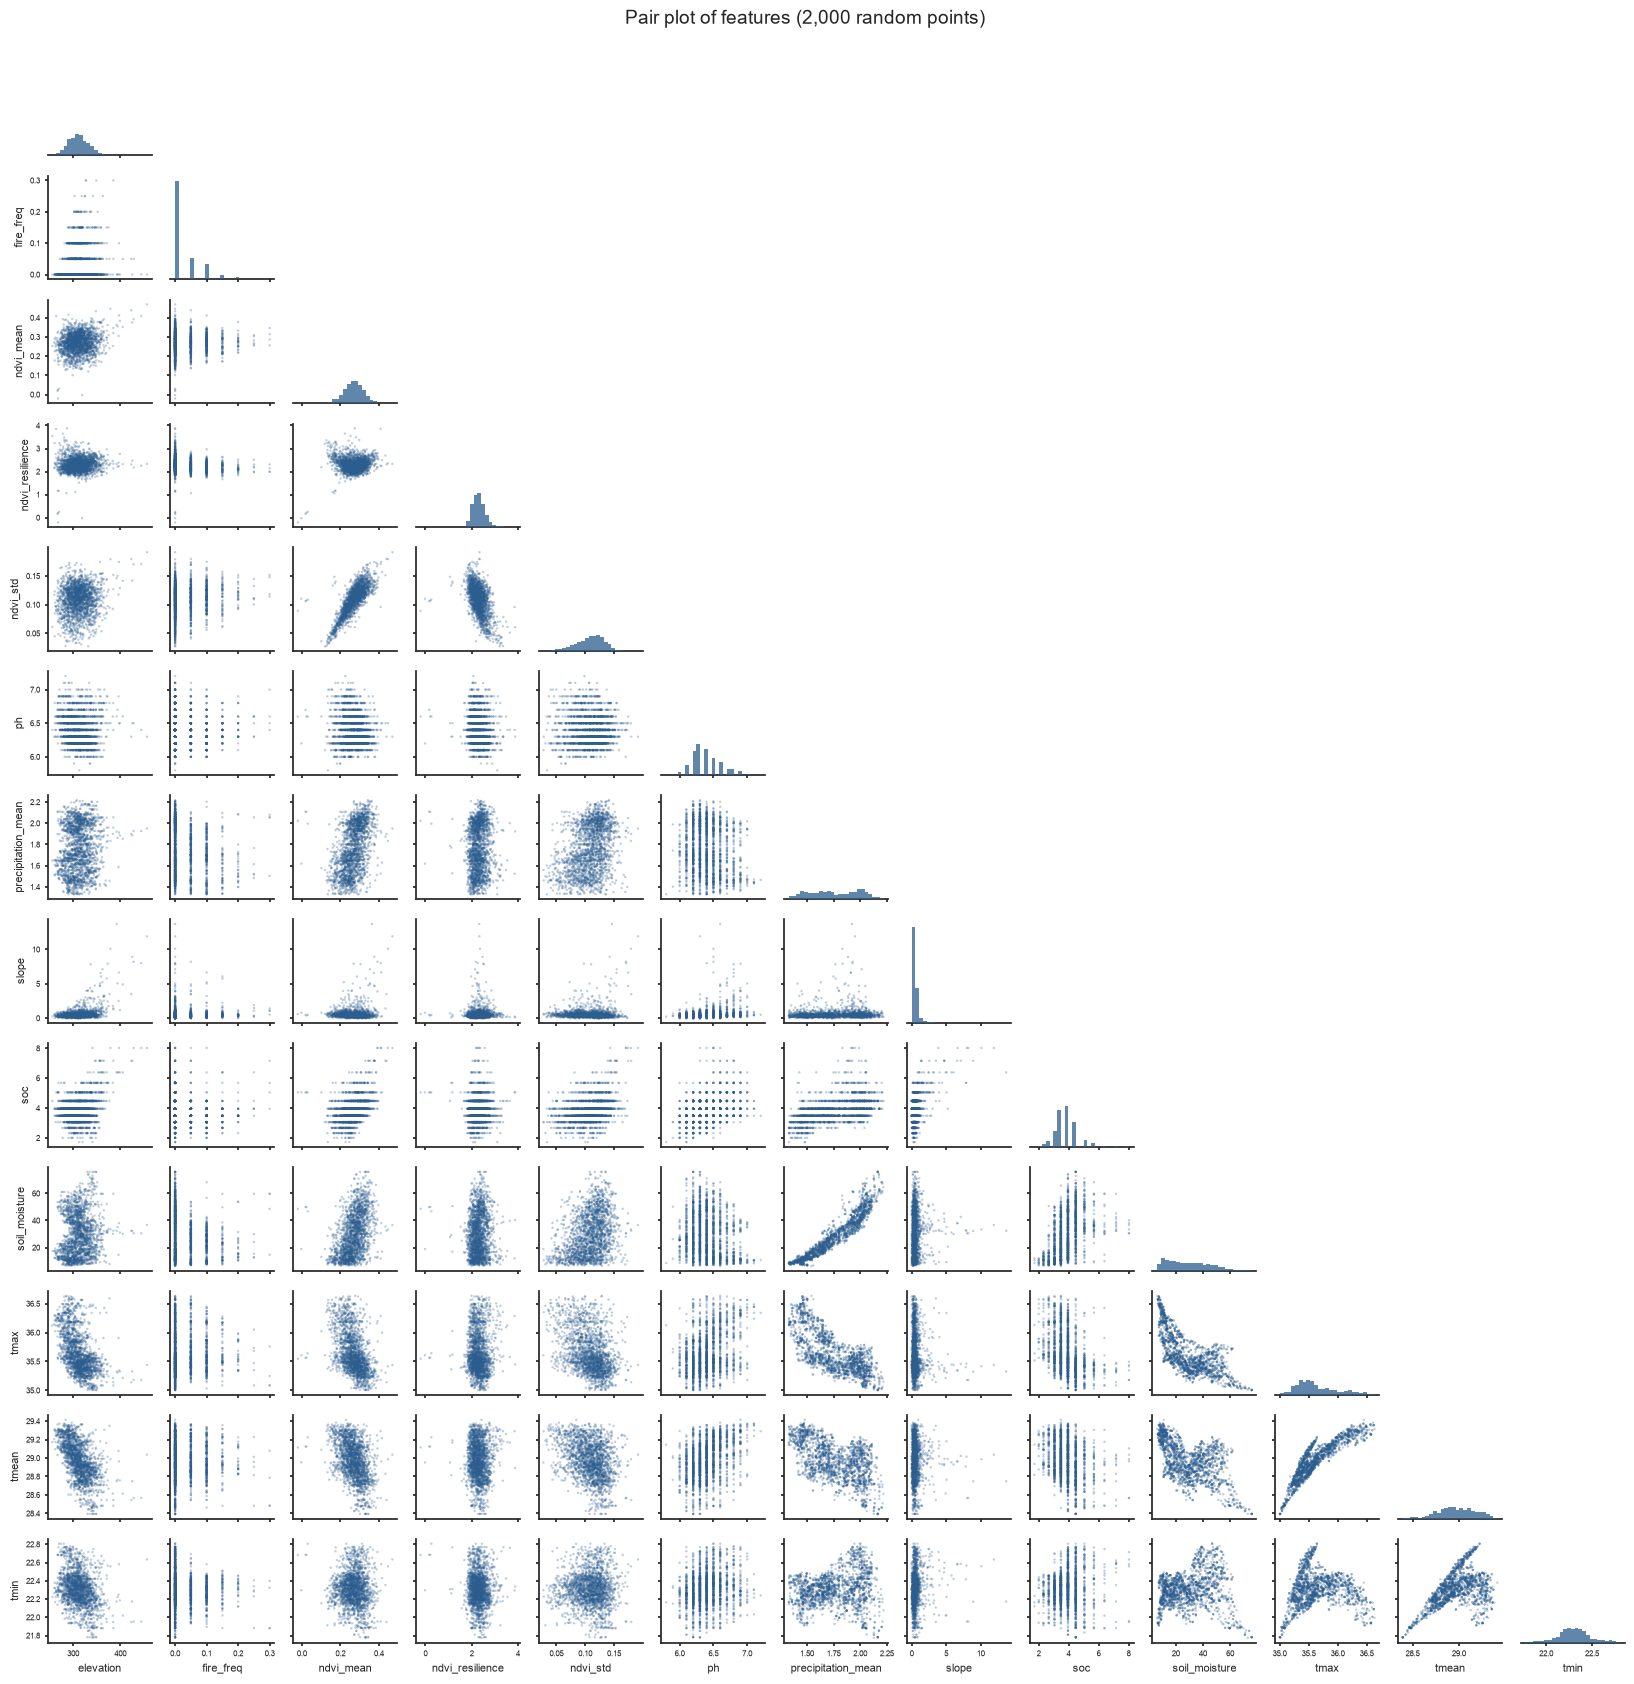

Week 1 EDA Report complete. Figures saved to 'reports/figures/'


In [58]:
from matplotlib.ticker import MaxNLocator

SCALE_TS = 1000   # metres, for the yearly series
REDUCER = ee.Reducer.mean().combine(ee.Reducer.percentile([10, 90]), sharedInputs=True)
EMPTY = ee.Image.constant(0).updateMask(ee.Image.constant(0))   # fully masked image
YEARS = range(min(CLIMATE_YEARS[0], NDVI_YEARS[0], FIRE_LONG_YEARS[0]),
              max(CLIMATE_YEARS[1], NDVI_YEARS[1], FIRE_LONG_YEARS[1]) + 1)


def year_col(col_id, band, y):
    start = ee.Date.fromYMD(y, 1, 1)
    return ee.ImageCollection(col_id).select(band).filterDate(start, start.advance(1, "year"))


def guarded(col, build, names):
    """Build an image from a collection, or a masked placeholder if the collection is empty."""
    empty = ee.Image.cat([EMPTY.rename(n) for n in names])
    return ee.Image(ee.Algorithms.If(col.size().gt(0), build(col), empty))


def year_stack(y):
    """All time-varying features for one full calendar year."""
    precip = guarded(year_col("UCSB-CHG/CHIRPS/DAILY", "precipitation", y),
                     lambda c: c.sum().rename("precipitation"), ["precipitation"])

    def build_tc(c):
        m = c.mean()
        tmin = m.select("tmmn").multiply(0.1)          # TerraClimate scale 0.1
        tmax = m.select("tmmx").multiply(0.1)
        return ee.Image.cat([
            tmin.rename("tmin"), tmax.rename("tmax"),
            tmin.add(tmax).divide(2).rename("tmean"),
            m.select("soil").multiply(0.1).rename("soil_moisture"),
        ])
    tc = guarded(year_col("IDAHO_EPSCOR/TERRACLIMATE", ["tmmn", "tmmx", "soil"], y),
                 build_tc, ["tmin", "tmax", "tmean", "soil_moisture"])

    burn = guarded(year_col("MODIS/061/MCD64A1", "BurnDate", y),
                   lambda c: c.max().gt(0).unmask(0).rename("fire_freq"), ["fire_freq"])

    def build_ndvi(c):
        c = c.map(lambda i: i.multiply(0.0001))
        r = c.reduce(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True))
        m = r.select("NDVI_mean").rename("ndvi_mean")
        s = r.select("NDVI_stdDev").rename("ndvi_std")
        return ee.Image.cat([m, s, m.divide(s.add(0.01)).rename("ndvi_resilience")])
    ndvi = guarded(year_col("MODIS/061/MOD13Q1", "NDVI", y),
                   build_ndvi, ["ndvi_mean", "ndvi_std", "ndvi_resilience"])

    return ee.Image.cat([precip, tc, burn, ndvi])


# ======================= PART 1: yearly series (cached, resumable) =======================
cache = DATA_PROCESSED / "timeseries_all_features.csv"
done = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["year"])
rows = done.to_dict("records")
have = set(done["year"].astype(int))

for y in YEARS:
    if y in have:
        continue
    print(f"Fetching {y} ...")
    stats = year_stack(y).reduceRegion(reducer=REDUCER, geometry=aoi_ee, scale=SCALE_TS,
                                       maxPixels=1e9, tileScale=4, bestEffort=True).getInfo()
    rows.append({"year": y, **stats})
    pd.DataFrame(rows).sort_values("year").to_csv(cache, index=False)   # save after every year

ts = pd.DataFrame(rows).sort_values("year").reset_index(drop=True)

# ---- burned area instead of fraction (converted locally from the cached fraction) ----
BURNED_UNIT = "km2"      # "km2" -> burned area in km2 | "pct" -> % of the AOI
AOI_KM2 = aoi_gdf.to_crs(aoi_gdf.estimate_utm_crs()).area.sum() / 1e6
if BURNED_UNIT == "km2":
    ts["burned_area_mean"] = ts["fire_freq_mean"] * AOI_KM2
    burned_label = "km² burned per year"
else:
    ts["burned_area_mean"] = ts["fire_freq_mean"] * 100
    burned_label = "% of AOI burned per year"
print(f"AOI area: {AOI_KM2:,.0f} km²")

# (column, title, y-label, colour, show spatial-spread band)
ANNUAL_PANELS = [
    ("precipitation",   "Annual rainfall (CHIRPS)",              "mm / year",    "tab:blue",   True),
    ("tmean",           "Mean temperature (TerraClimate)",       "°C",           "tab:orange", True),
    ("tmin",            "Minimum temperature",                   "°C",           "tab:cyan",   True),
    ("tmax",            "Maximum temperature",                   "°C",           "tab:red",    True),
    ("soil_moisture",   "Soil moisture (TerraClimate)",          "mm",           "tab:brown",  True),
    ("burned_area",     "Burned area per year (MODIS MCD64A1)",  burned_label,   "firebrick",  False),
    ("ndvi_mean",       "NDVI mean (MODIS, all months)",         "NDVI",         "tab:green",  True),
    ("ndvi_std",        "NDVI variability within year (std)",    "NDVI",         "tab:purple", True),
    ("ndvi_resilience", "NDVI resilience = mean / (std + 0.01)", "ratio",        "indigo",     True),
]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, (col, title, ylabel, color, band) in zip(axes.ravel(), ANNUAL_PANELS):
    ok = ts.dropna(subset=[f"{col}_mean"])
    ax.plot(ok["year"], ok[f"{col}_mean"], marker="o", color=color,
            label="AOI mean" if band else "AOI total")
    if band:
        ax.fill_between(ok["year"], ok[f"{col}_p10"], ok[f"{col}_p90"], color=color, alpha=0.2,
                        label="10th-90th percentile (spatial spread)")
    if len(ok) >= 3:
        s, b = np.polyfit(ok["year"], ok[f"{col}_mean"], 1)
        ax.plot(ok["year"], s * ok["year"] + b, "--", color="black", lw=1,
                label=f"trend: {s * 10:+.3g} per decade")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=7)
                


plt.tight_layout()
plt.savefig(FIGURES / "01a_time_varying_features_by_year.png", dpi=300)
plt.show()

# ======================= PART 2: static features (real values of the sampled points) =======================
src = gdf

# (column, title, x-label, colour)
STATIC_PANELS = [
    ("soc",            "Soil organic carbon (iSDAsoil)",  "g/kg",    "saddlebrown"),
    ("ph",             "Soil pH (iSDAsoil)",              "pH",      "tab:olive"),
    ("elevation",      "Elevation (SRTM)",                "m",       "tab:gray"),
    ("slope",          "Slope (SRTM)",                    "degrees", "dimgray"),
    ("dist_to_road_m", "Distance to nearest road (OSM)",  "metres",  "tab:orange"),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, title, xlabel, color) in zip(axes.ravel(), STATIC_PANELS):
    vals = src[col].dropna() if col in src.columns else pd.Series(dtype=float)
    if vals.empty:
        ax.text(0.5, 0.5, f"'{col}' missing or all NaN", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, fontsize=10)
        continue
    sns.histplot(vals, bins=40, color=color, ax=ax)
    ax.axvline(vals.mean(), color="black", ls="--", lw=1, label=f"mean {vals.mean():.2f}")
    ax.axvline(vals.median(), color="red", ls=":", lw=1.5, label=f"median {vals.median():.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of sampled points")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(STATIC_PANELS):]:     # hide the unused panel
    ax.set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / "01b_static_feature_distributions.png", dpi=300)
plt.show()

# ======================= PART 3: summary tables of the real values =======================
START, END = 2006, 2025

static_cols = [c for c, *_ in STATIC_PANELS if c in src.columns]
print("STATIC FEATURES (sampled points)")
print(src[static_cols].describe().round(2))

ts_period = ts[(ts["year"] >= START) & (ts["year"] <= END)]
annual_cols = [f"{c}_mean" for c, *_ in ANNUAL_PANELS if f"{c}_mean" in ts_period.columns]
yearly = ts_period[annual_cols].rename(columns=lambda c: c.replace("_mean", ""))
print(f"\nYEARLY FEATURES (AOI mean per year, {START}-{END}; burned_area in {burned_label.split(' per')[0]})")
print(yearly.describe().round(2))

mean_table = pd.DataFrame({f"mean_{START}_{END}": yearly.mean().round(3), "n_years": yearly.count()})
print(f"\nMEAN OF THE WHOLE {START}-{END} SERIES")
print(mean_table)

static_means = src[static_cols].mean().round(3).rename("value")
combined = pd.concat([
    mean_table[f"mean_{START}_{END}"].rename("value").to_frame().assign(type=f"yearly mean {START}-{END}"),
    static_means.to_frame().assign(type="static (sampled points)"),
])
combined.to_csv(DATA_PROCESSED / "feature_means_summary.csv")
print(f"\nSaved: {DATA_PROCESSED / 'feature_means_summary.csv'}")

# ======================= PART 4: correlation matrix + pair plot =======================
# Not included: dummy, aspect, built_up, water, protected, dist_to_road_m, dist_to_settlement_m, proxy_target
FEATURES = ["elevation", "fire_freq", "ndvi_mean", "ndvi_resilience", "ndvi_std", "ph",
            "precipitation_mean", "slope", "soc", "soil_moisture", "tmax", "tmean", "tmin"]   # alphabetical
SHOW_DIAGONAL = True      # True: diagonal shows 1.00 | False: hidden, exactly like your reference image
PAIR_SAMPLE = 2000        # points used in the pair plot

df = gdf[[c for c in FEATURES if c in gdf.columns]].copy()
not_in_df = [c for c in FEATURES if c not in gdf.columns]
all_nan = [c for c in df.columns if df[c].isna().all()]
constant = [c for c in df.columns if c not in all_nan and df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=all_nan + constant)

print(f"\nFeatures used for correlation/pair plot: {df.shape[1]} of {len(FEATURES)}")
if not_in_df: print("  not in dataframe  :", not_in_df)
if all_nan:   print("  all NaN (dropped) :", all_nan)
if constant:  print("  constant (dropped):", constant)

# ---- correlation matrix ----
corr = df.corr(method="spearman")                         # NaNs handled pairwise, robust to skew
m = len(corr)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1 if SHOW_DIAGONAL else 0)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(FIGURES / "02_correlation_matrix.png", dpi=300)
plt.show()

pairs = corr.where(np.tril(np.ones((m, m), dtype=bool), k=-1)).stack().rename("rho").reset_index()
pairs.columns = ["feature_1", "feature_2", "rho"]
strong = pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
print("\nPairs with |rho| >= 0.8:")
print(strong.round(2).to_string(index=False) if not strong.empty else "none")

# ---- pair plot ----
sample = df.sample(min(PAIR_SAMPLE, len(df)), random_state=RANDOM_STATE)
sns.set_theme(style="ticks")
g = sns.pairplot(
    sample, corner=True, diag_kind="hist", height=1.3,
    plot_kws=dict(s=3, alpha=0.3, edgecolor="none", rasterized=True, color="#2c5d8f"),
    diag_kws=dict(bins=25, edgecolor="none", color="#2c5d8f"),
)
for a in g.axes.flatten():
    if a is not None:
        a.tick_params(labelsize=6, length=2)
        a.xaxis.label.set_size(8)
        a.yaxis.label.set_size(8)
g.figure.suptitle(f"Pair plot of features ({len(sample):,} random points)", y=1.01, fontsize=14)
g.savefig(FIGURES / "02b_pairplot_features.png", dpi=200, bbox_inches="tight")
plt.show()

print("Week 1 EDA Report complete. Figures saved to 'reports/figures/'")

In [59]:
gdf = gdf.drop(columns=["dummy", "proxy_target"], errors="ignore")
print(gdf.columns.tolist())

['geometry', 'built_up', 'elevation', 'fire_freq', 'ndvi_mean', 'ndvi_resilience', 'ndvi_std', 'ndvi_trend', 'ph', 'precipitation_mean', 'protected', 'slope', 'soc', 'soil_moisture', 'tmax', 'tmean', 'tmin', 'water', 'dist_to_road_m', 'dist_to_settlement_m']


In [60]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 9903 entries, 0 to 9902
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   geometry              9903 non-null   geometry
 1   built_up              9903 non-null   int64   
 2   elevation             9903 non-null   int64   
 3   fire_freq             9903 non-null   float64 
 4   ndvi_mean             9903 non-null   float64 
 5   ndvi_resilience       9903 non-null   float64 
 6   ndvi_std              9903 non-null   float64 
 7   ndvi_trend            9903 non-null   float64 
 8   ph                    9903 non-null   float64 
 9   precipitation_mean    9903 non-null   float64 
 10  protected             9903 non-null   int64   
 11  slope                 9903 non-null   float64 
 12  soc                   9903 non-null   float64 
 13  soil_moisture         9903 non-null   float64 
 14  tmax                  9903 non-null   float64 
 

# Modelling

In [61]:
import re
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import ee
import geemap
import torch
import torch.nn as nn
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, ParameterSampler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, f1_score, accuracy_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

In [71]:
# ============================ SETTINGS ============================
LABEL_COL = "ndvi_trend"          # outcome that defines the label (NDVI change per year, 2006-2025)
HIGH_Q, LOW_Q = 0.70, 0.30        # top 30% = high potential (1), bottom 30% = low potential (0)
BLOCK_M = 10_000                  # spatial block size in metres
TEST_SIZE = 0.30                  # share of blocks held out for the final test
N_ITER = 20                       # random-search iterations per tabular model (lower it to run faster)
N_ITER_PATCH = 6                  # random-search configurations for the patch CNN (each is trained 5 times)
CANDIDATES = ["precipitation_mean", "soil_moisture", "tmean", "soc", "ph",
              "elevation", "slope", "dist_to_road_m", 'built_up', 'ndvi_mean', 
              'ndvi_resilience', 'ndvi_std', 'protected',  'tmax', 
              'tmin', 'water', 'dist_to_settlement_m']
# Not predictors: ndvi_trend (defines the label), ndvi_mean / ndvi_std / ndvi_resilience (same NDVI signal),
# fire_freq (kept for the separate Risk Score), tmin / tmax (near-duplicates of tmean)

# ---- spatial CNN: image patches around every point ----
PATCH_RADIUS = 2                  # 2 -> 5 x 5 pixels (1.25 km window at 250 m); 3 -> 7 x 7
PATCH_BANDS = ["precipitation_mean", "soil_moisture", "tmean", "soc", "ph", "elevation", "slope"]
COARSE_BANDS = {"precipitation_mean", "soil_moisture", "tmean"}   # 4-5 km sources: interpolate, do not aggregate
SCALAR_FEATURES = [c for c in ["dist_to_road_m"] if c in CANDIDATES]   # local OSM feature, fed next to the patch
BATCH = 500                       # points per Earth Engine request (lower it if you get memory errors)
CNN_NAME = "CNN (2D patches)"
slug = lambda s: re.sub(r"\W+", "_", s.lower()).strip("_")

In [72]:
# ============================ 1. DATA ============================
data = gdf.drop(columns=["dummy", "proxy_target"], errors="ignore").copy()
assert data.index.is_unique, "gdf index must be unique (it is used as the point id for the patches)"

utm = data.estimate_utm_crs()                                   # metric CRS for block sizes
xy_utm = data.to_crs(utm).geometry
data["x_m"], data["y_m"] = xy_utm.x.values, xy_utm.y.values
data["block"] = ((data["x_m"] // BLOCK_M).astype(int).astype(str) + "_" +
                 (data["y_m"] // BLOCK_M).astype(int).astype(str))

PREDICTORS = [c for c in CANDIDATES if c in data.columns and data[c].notna().mean() > 0.95]
SCALAR_FEATURES = [c for c in SCALAR_FEATURES if c in PREDICTORS]
print("Predictors used:", PREDICTORS)
print("Left out        :", [c for c in CANDIDATES if c not in PREDICTORS])


Predictors used: ['precipitation_mean', 'soil_moisture', 'tmean', 'soc', 'ph', 'elevation', 'slope', 'dist_to_road_m', 'built_up', 'ndvi_mean', 'ndvi_resilience', 'ndvi_std', 'protected', 'tmax', 'tmin', 'water']
Left out        : ['dist_to_settlement_m']


In [74]:

# ============================ 2. IMAGE PATCHES FROM EARTH ENGINE (cached, resumable) ============================
R, H, C = PATCH_RADIUS, 2 * PATCH_RADIUS + 1, len(PATCH_BANDS)
PATCH_DIR = DATA_PROCESSED / "patches"; PATCH_DIR.mkdir(parents=True, exist_ok=True)
crs = utm.to_string()                                           # e.g. "EPSG:32630"

src = features_image if "features_image" in globals() else get_features_image(aoi_gdf)

def on_grid(band):
    """One band on the common UTM 250 m grid: fine layers are averaged, coarse climate layers are interpolated."""
    b = src.select(band)
    if band in COARSE_BANDS:
        return b.resample("bilinear").reproject(crs=crs, scale=TARGET_SCALE)
    return b.reduceResolution(ee.Reducer.mean(), maxPixels=256).reproject(crs=crs, scale=TARGET_SCALE)

# every output band is named "<band>_<x>_<y>" with offsets from -R to +R pixels around the point
patch_img = ee.Image.cat([on_grid(b) for b in PATCH_BANDS]).neighborhoodToBands(ee.Kernel.square(R, "pixels"))

band_idx = {b: i for i, b in enumerate(PATCH_BANDS)}
name_rx = re.compile(r"^(.*)_(-?\d+)_(-?\d+)$")

def fetch_batch(batch):
    fc = geemap.gdf_to_ee(batch[["pid", "geometry"]])
    for attempt in range(3):
        try:
            return patch_img.sampleRegions(collection=fc, properties=["pid"], scale=TARGET_SCALE,
                                           tileScale=4, geometries=False).getInfo()["features"]
        except Exception as e:
            print(f"   attempt {attempt + 1}/3 failed: {str(e)[:150]}")
            time.sleep(10 * (attempt + 1))
    raise RuntimeError("Earth Engine batch failed three times")

def parse_batch(features):
    pids, arrs = [], []
    for f in features:
        p = f["properties"]
        a = np.full((C, H, H), np.nan, dtype=np.float32)
        for k, v in p.items():
            mt = name_rx.match(k)
            if mt and mt.group(1) in band_idx and v is not None:
                a[band_idx[mt.group(1)], int(mt.group(3)) + R, int(mt.group(2)) + R] = v   # [channel, row(y), col(x)]
        pids.append(int(p["pid"])); arrs.append(a)
    if not arrs:
        return np.array([], dtype=int), np.zeros((0, C, H, H), dtype=np.float32)
    return np.array(pids), np.stack(arrs)

pid_df = data[["geometry"]].copy()
pid_df["pid"] = data.index.astype(int)
n_batches = int(np.ceil(len(pid_df) / BATCH))
print(f"\nFetching {H}x{H} patches of {C} layers for {len(pid_df)} points in {n_batches} batches (cached, resumable)")
for i in range(n_batches):
    fpath = PATCH_DIR / f"r{R}_batch_{i:04d}.npz"
    if fpath.exists():
        continue
    t0 = time.perf_counter()
    pid_b, arr_b = parse_batch(fetch_batch(pid_df.iloc[i * BATCH:(i + 1) * BATCH]))
    np.savez_compressed(fpath, pid=pid_b, patch=arr_b)
    print(f"  batch {i + 1}/{n_batches}: {len(pid_b)} patches in {time.perf_counter() - t0:.0f}s")

loaded = [np.load(f) for f in sorted(PATCH_DIR.glob(f"r{R}_batch_*.npz"))]
pid_all = np.concatenate([z["pid"] for z in loaded])
P_raw = np.concatenate([z["patch"] for z in loaded])
pos = pd.Series(np.arange(len(pid_all)), index=pid_all).reindex(data.index.astype(int))
P_all = np.full((len(data), C, H, H), np.nan, dtype=np.float32)       # aligned with the rows of `data`
have = pos.notna().values
P_all[have] = P_raw[pos[have].astype(int).values]
print(f"Patches received for {have.sum()} of {len(data)} points")

# fill gaps (points near the edge of the data): patch-channel mean first, then the global channel mean
n_gap = int(np.isnan(P_all).any(axis=(1, 2, 3)).sum())
P_all = np.where(np.isnan(P_all), np.nanmean(P_all, axis=(2, 3), keepdims=True), P_all)
P_all = np.where(np.isnan(P_all), np.nanmean(P_all, axis=(0, 2, 3), keepdims=True), P_all).astype(np.float32)
print(f"Patches with gaps that were filled: {n_gap} ({n_gap / len(data) * 100:.1f}%)")

# sanity check: the centre pixel must agree with the value sampled earlier at the same point
print("Centre pixel vs. data column (correlation) - should be close to 1 for every layer:")
for b, j in band_idx.items():
    if b in data.columns:
        ok_ = data[b].notna().values & have
        print(f"  {b:20s} r = {np.corrcoef(P_all[ok_, j, R, R], data.loc[ok_, b])[0, 1]:.3f}")
np.save(PATCH_DIR / f"P_all_r{R}.npy", P_all)


Fetching 5x5 patches of 7 layers for 9903 points in 20 batches (cached, resumable)
Patches received for 9865 of 9903 points
Patches with gaps that were filled: 38 (0.4%)
Centre pixel vs. data column (correlation) - should be close to 1 for every layer:
  precipitation_mean   r = 0.970
  soil_moisture        r = 0.957
  tmean                r = 0.776
  soc                  r = 0.957
  ph                   r = 0.949
  elevation            r = 0.996
  slope                r = 0.739


In [75]:
# ============================ 3. LABEL FROM THE OUTCOME ============================
d = data.dropna(subset=[LABEL_COL] + PREDICTORS).copy()
lo, hi = d[LABEL_COL].quantile([LOW_Q, HIGH_Q])
d = d[(d[LABEL_COL] <= lo) | (d[LABEL_COL] >= hi)].copy()       # drop the ambiguous middle
d["label"] = (d[LABEL_COL] >= hi).astype(int)
print(f"\n{LABEL_COL}: low <= {lo:.4f}, high >= {hi:.4f} (NDVI units per year)")
print("Labelled points:", len(d)); print(d["label"].value_counts().rename({0: "low (0)", 1: "high (1)"}))

X, y, groups = d[PREDICTORS], d["label"], d["block"].values
row_pos = data.index.get_indexer(d.index)                       # position of each labelled point in `data` / P_all
P = P_all[row_pos]                                              # (n, channels, H, W)
S = d[SCALAR_FEATURES].to_numpy(np.float32).reshape(len(d), -1)


ndvi_trend: low <= 0.0012, high >= 0.0033 (NDVI units per year)
Labelled points: 5942
label
high (1)    2971
low (0)     2971
Name: count, dtype: int64


In [76]:
# ============================ 4. SPATIAL TRAIN / TEST SPLIT (whole blocks held out) ============================
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups[tr]
P_tr, P_te, S_tr, S_te = P[tr], P[te], S[tr], S[te]
y_tr_a, y_te_a = y_tr.to_numpy(), y_te.to_numpy()
print(f"\nTrain: {len(X_tr)} points in {len(set(g_tr))} blocks | Test: {len(X_te)} points in {len(set(groups[te]))} blocks")


Train: 4278 points in 273 blocks | Test: 1664 points in 117 blocks


In [77]:
# ============================ 5. THE 2D CNN ============================
class _Net(nn.Module):
    def __init__(self, c_in, n_scalar, filters, dropout):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(c_in, filters, 3, padding=1), nn.BatchNorm2d(filters), nn.ReLU(),
            nn.Conv2d(filters, filters * 2, 3, padding=1), nn.BatchNorm2d(filters * 2), nn.ReLU(),
            nn.AdaptiveAvgPool2d(2), nn.Flatten())                       # 2x2 summary, any patch size works
        self.head = nn.Sequential(nn.Linear(filters * 2 * 4 + n_scalar, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, s):
        z = self.conv(x)
        if s.shape[1] > 0:
            z = torch.cat([z, s], dim=1)                                 # patch features + road distance
        return self.head(z).squeeze(1)


class PatchCNN:
    """2D CNN on (channels x H x W) patches + optional scalar features. Early stopping uses whole held-out BLOCKS."""

    def __init__(self, filters=32, dropout=0.3, lr=1e-3, weight_decay=1e-4, epochs=60,
                 batch_size=64, patience=8, augment=True, seed=0):
        self.filters, self.dropout, self.lr, self.weight_decay = filters, dropout, lr, weight_decay
        self.epochs, self.batch_size, self.patience, self.augment, self.seed = epochs, batch_size, patience, augment, seed

    def _prep(self, P, S):
        P = (P - self.mu_[None, :, None, None]) / self.sd_[None, :, None, None]
        S = (np.log1p(np.clip(S, 0, None)) - self.smu_) / self.ssd_       # distances are skewed -> log, then standardise
        return torch.tensor(P, dtype=torch.float32), torch.tensor(S, dtype=torch.float32)

    def fit(self, P, S, y, groups):
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        torch.manual_seed(self.seed)
        self.mu_, self.sd_ = P.mean(axis=(0, 2, 3)), P.std(axis=(0, 2, 3)) + 1e-6
        Sl = np.log1p(np.clip(S, 0, None))
        self.smu_, self.ssd_ = Sl.mean(axis=0), Sl.std(axis=0) + 1e-6

        ug = np.unique(groups); rng = np.random.RandomState(self.seed); rng.shuffle(ug)
        val_blocks = set(ug[:max(int(0.15 * len(ug)), 1)])                # 15% of the BLOCKS for early stopping
        is_val = np.array([g in val_blocks for g in groups])
        Xp, Xs = self._prep(P, S)
        yt = torch.tensor(y, dtype=torch.float32)
        tri, vai = np.where(~is_val)[0], np.where(is_val)[0]
        Xp_t, Xs_t, y_t = Xp[tri].to(dev), Xs[tri].to(dev), yt[tri].to(dev)
        Xp_v, Xs_v, y_v = Xp[vai].to(dev), Xs[vai].to(dev), yt[vai].to(dev)

        self.net_ = _Net(P.shape[1], S.shape[1], self.filters, self.dropout).to(dev)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        pos_w = torch.tensor([float((y[tri] == 0).sum() / max((y[tri] == 1).sum(), 1))], device=dev)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)

        best, best_state, wait = float("inf"), None, 0
        for _ in range(self.epochs):
            self.net_.train()
            order = torch.randperm(len(Xp_t), device=dev)
            for i in range(0, len(order), self.batch_size):
                idx = order[i:i + self.batch_size]
                if len(idx) < 2:                                          # BatchNorm needs at least 2 samples
                    continue
                xb = Xp_t[idx]
                if self.augment:                                          # random rotation / flip of the whole batch
                    xb = torch.rot90(xb, int(torch.randint(0, 4, (1,))), dims=(2, 3))
                    if torch.rand(1).item() < 0.5:
                        xb = torch.flip(xb, dims=(3,))
                opt.zero_grad()
                loss_fn(self.net_(xb, Xs_t[idx]), y_t[idx]).backward()
                opt.step()
            self.net_.eval()
            with torch.no_grad():
                v = loss_fn(self.net_(Xp_v, Xs_v), y_v).item()
            if v < best - 1e-4:
                best, wait = v, 0
                best_state = {k: t.detach().clone() for k, t in self.net_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net_.load_state_dict(best_state)
        self.net_.cpu().eval()
        return self

    def predict_proba(self, P, S):
        Xp, Xs = self._prep(P, S)
        out = []
        with torch.no_grad():
            for i in range(0, len(Xp), 1024):
                out.append(torch.sigmoid(self.net_(Xp[i:i + 1024], Xs[i:i + 1024])).numpy())
        return np.concatenate(out)



In [78]:
# ============================ 5b. MAKE THE CNN A scikit-learn MODEL (so it can live in MODELS) ============================
class PatchStore:
    """Holds the image patches and block ids of ALL points; rows are looked up by the DataFrame index."""
    def __init__(self, patches, index, blocks):
        self.patches, self.index, self.blocks = patches, pd.Index(index), np.asarray(blocks)

    def get(self, idx):
        pos = self.index.get_indexer(idx)
        assert (pos >= 0).all(), "some rows have no patch"
        return self.patches[pos], self.blocks[pos]

    def __deepcopy__(self, memo):            # sklearn's clone() would otherwise copy every patch for every single fit
        return self


class PatchCNNClassifier(ClassifierMixin, BaseEstimator):
    """Takes the usual table X (index = point id). The patch of every row comes from the PatchStore,
    the scalar inputs (e.g. road distance) come from X[scalar_cols]. Early stopping uses whole blocks."""

    def __init__(self, store=None, scalar_cols=(), filters=32, dropout=0.3, lr=1e-3, weight_decay=1e-4,
                 epochs=60, batch_size=64, patience=8, augment=True, random_state=0):
        self.store, self.scalar_cols = store, scalar_cols
        self.filters, self.dropout, self.lr, self.weight_decay = filters, dropout, lr, weight_decay
        self.epochs, self.batch_size, self.patience, self.augment = epochs, batch_size, patience, augment
        self.random_state = random_state

    def _inputs(self, X):
        P, g = self.store.get(X.index)
        S = X[list(self.scalar_cols)].to_numpy(np.float32).reshape(len(X), -1)
        return P, S, g

    def fit(self, X, y):
        P, S, g = self._inputs(X)
        self.classes_ = np.array([0, 1])
        self.core_ = PatchCNN(filters=self.filters, dropout=self.dropout, lr=self.lr,
                              weight_decay=self.weight_decay, epochs=self.epochs, batch_size=self.batch_size,
                              patience=self.patience, augment=self.augment, seed=self.random_state
                              ).fit(P, S, np.asarray(y), g)
        return self

    def predict_proba(self, X):
        P, S, _ = self._inputs(X)
        p = self.core_.predict_proba(P, S)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [79]:
# ============================ 6. ALL MODELS + SEARCH SPACES ============================
pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)       # for XGBoost class balance
PATCH_STORE = PatchStore(P_all, data.index, data["block"].values)

MODELS = {
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        {"n_estimators": [300, 500, 800], "max_depth": [None, 6, 10, 16],
         "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5]}),
    "Logistic Regression": (                                     # scaling matters here, trees don't need it
        Pipeline([("scale", PowerTransformer()),                 # standardises and reduces skew (e.g. distances)
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}),
    "XGBoost": (
        XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                      scale_pos_weight=pos_weight, n_jobs=-1, random_state=RANDOM_STATE),
        {"n_estimators": [200, 400, 600], "max_depth": [3, 4, 6, 8],
         "learning_rate": [0.01, 0.03, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0],
         "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5], "reg_lambda": [1, 5, 10]}),
    CNN_NAME: (                                                  # the spatial CNN, now a normal entry
        PatchCNNClassifier(store=PATCH_STORE, scalar_cols=tuple(SCALAR_FEATURES), random_state=RANDOM_STATE),
        {"filters": [16, 32, 48], "dropout": [0.2, 0.4, 0.5], "lr": [3e-4, 1e-3, 3e-3],
         "weight_decay": [1e-5, 1e-4, 1e-3]}),
}
N_ITER_BY_MODEL = {CNN_NAME: N_ITER_PATCH}                       # the CNN is slower, so it gets fewer configurations


In [80]:
# ============================ 7. TUNE EACH MODEL (spatial CV inside the training blocks only) ============================
cv = GroupKFold(n_splits=5)
fitted, proba, pred, result_rows = {}, {}, {}, []

def macro_f1(y_true, p):
    return f1_score(y_true, (p >= 0.5).astype(int), average="macro")

def score_row(name, cv_f1, p, t0):
    return {"model": name, "CV F1 macro": cv_f1,
            "Test accuracy": accuracy_score(y_te_a, (p >= 0.5).astype(int)),
            "Test F1 macro": macro_f1(y_te_a, p),
            "Test ROC-AUC": roc_auc_score(y_te_a, p),
            "Test PR-AUC": average_precision_score(y_te_a, p),
            "seconds": time.perf_counter() - t0}

for name, (est, grid) in MODELS.items():
    t0 = time.perf_counter()
    n_iter = min(N_ITER_BY_MODEL.get(name, N_ITER), int(np.prod([len(v) for v in grid.values()])))
    s = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring="f1_macro", cv=cv,
                           random_state=RANDOM_STATE, n_jobs=1)
    s.fit(X_tr, y_tr, groups=g_tr)
    fitted[name] = s.best_estimator_
    proba[name] = fitted[name].predict_proba(X_te)[:, 1]
    pred[name] = fitted[name].predict(X_te)
    result_rows.append(score_row(name, s.best_score_, proba[name], t0))
    print(f"{name:20s} best params: {s.best_params_}")

res = pd.DataFrame(result_rows).set_index("model")
pd.set_option("display.width", 200)
print("\nRESULTS (targets: F1 macro > 0.75, ROC-AUC > 0.80)")
print(res.round(3).to_string())

# the best model is chosen on the spatial-CV score, NOT on the test score (the test set is used once, for reporting)
best_name = res["CV F1 macro"].idxmax()
print(f"\nBest model by spatial CV: {best_name}")
print(classification_report(y_te_a, pred[best_name], target_names=["low (0)", "high (1)"], digits=3))

Random Forest        best params: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 16}
Logistic Regression  best params: {'clf__C': 1}
XGBoost              best params: {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
CNN (2D patches)     best params: {'weight_decay': 0.0001, 'lr': 0.001, 'filters': 16, 'dropout': 0.4}

RESULTS (targets: F1 macro > 0.75, ROC-AUC > 0.80)
                     CV F1 macro  Test accuracy  Test F1 macro  Test ROC-AUC  Test PR-AUC  seconds
model                                                                                             
Random Forest              0.869          0.892          0.892         0.948        0.951  216.367
Logistic Regression        0.841          0.832          0.832         0.896        0.886   19.968
XGBoost                    0.866          0.872          0.872         0.942        0.948   83.672
CNN (

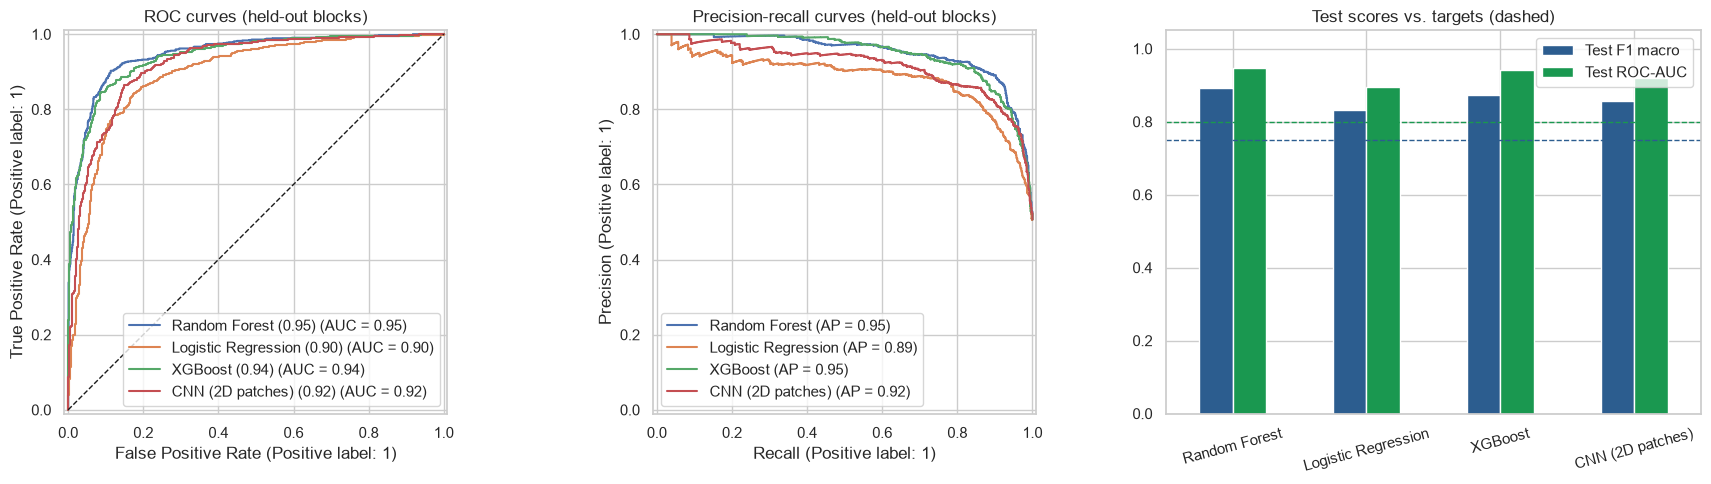

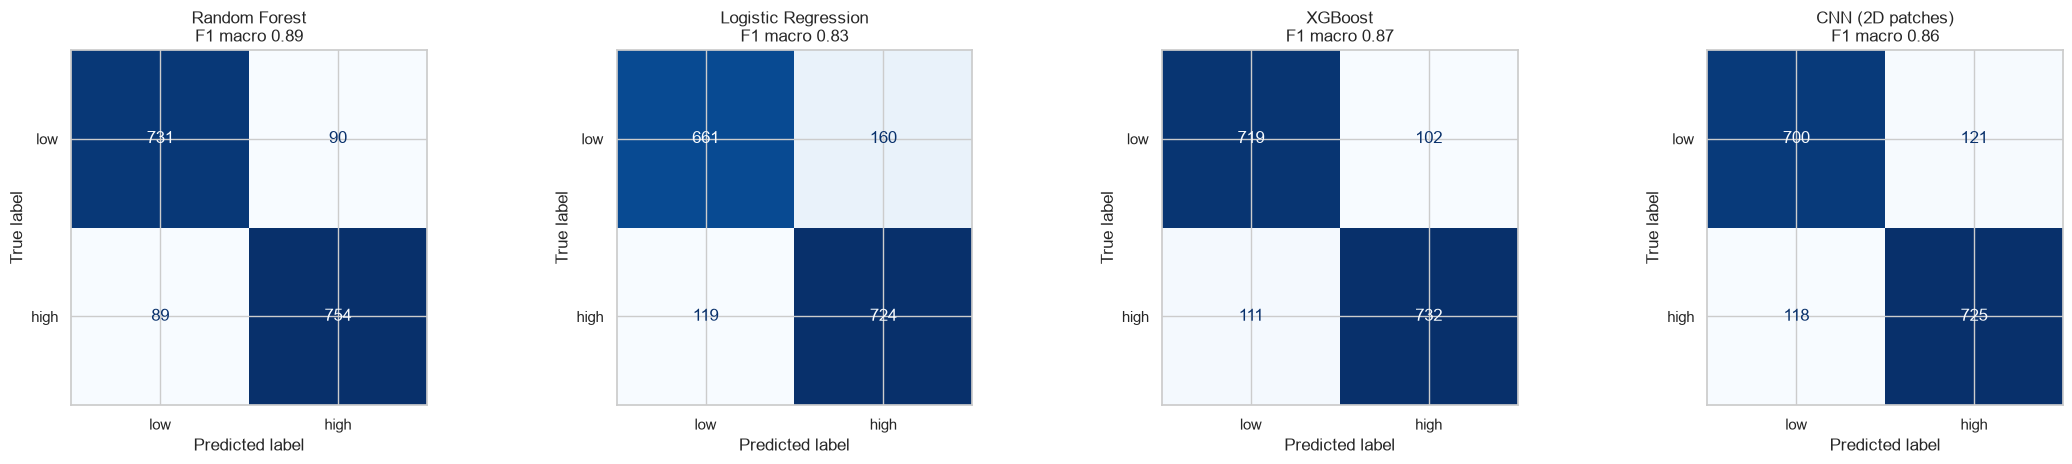

In [81]:
# ============================ 8. COMPARISON PLOTS ============================
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for name in proba:
    RocCurveDisplay.from_predictions(y_te_a, proba[name], ax=ax[0], name=f"{name} ({res.loc[name, 'Test ROC-AUC']:.2f})")
    PrecisionRecallDisplay.from_predictions(y_te_a, proba[name], ax=ax[1], name=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curves (held-out blocks)")
ax[1].set_title("Precision-recall curves (held-out blocks)")
res[["Test F1 macro", "Test ROC-AUC"]].plot.bar(ax=ax[2], rot=15, color=["#2c5d8f", "#1a9850"])
ax[2].axhline(0.75, color="#2c5d8f", ls="--", lw=1); ax[2].axhline(0.80, color="#1a9850", ls="--", lw=1)
ax[2].set_ylim(0, 1.05); ax[2].set_title("Test scores vs. targets (dashed)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES / "05a_model_comparison.png", dpi=300); plt.show()

fig, ax = plt.subplots(1, len(proba), figsize=(5.5 * len(proba), 4.8))
for a, name in zip(np.atleast_1d(ax), proba):
    ConfusionMatrixDisplay(confusion_matrix(y_te_a, pred[name]), display_labels=["low", "high"]).plot(
        ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{name}\nF1 macro {res.loc[name, 'Test F1 macro']:.2f}")
plt.tight_layout(); plt.savefig(FIGURES / "05b_confusion_matrices.png", dpi=300); plt.show()

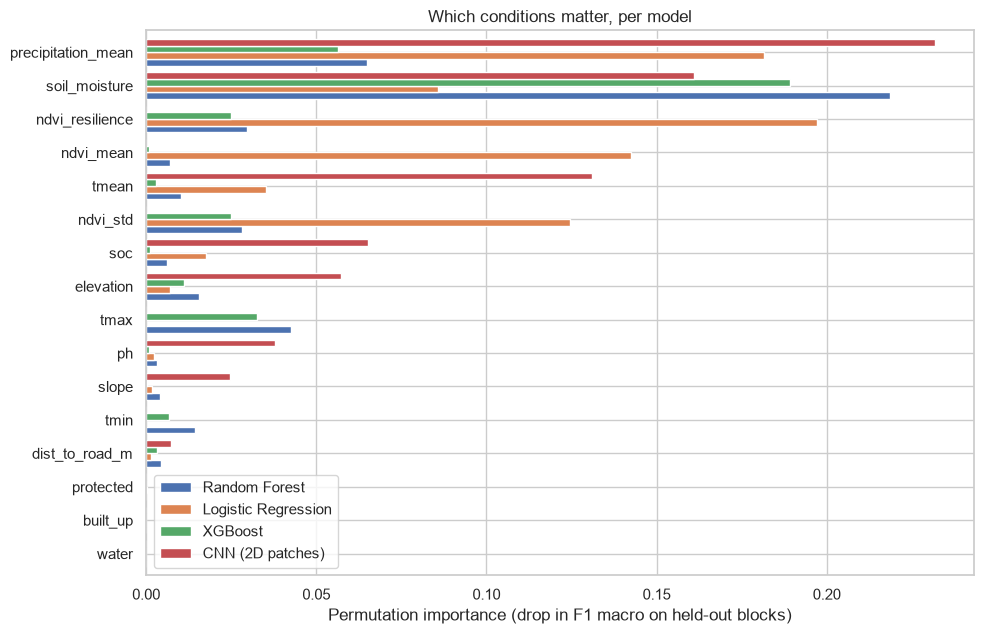


Permutation importance (held-out):
                    Random Forest  Logistic Regression  XGBoost  CNN (2D patches)
soil_moisture               0.218                0.086    0.189             0.161
precipitation_mean          0.065                0.182    0.056             0.232
tmax                        0.043                0.000    0.033               NaN
ndvi_resilience             0.030                0.197    0.025               NaN
ndvi_std                    0.028                0.124    0.025               NaN
elevation                   0.016                0.007    0.011             0.057
tmin                        0.014                0.000    0.007               NaN
tmean                       0.010                0.035    0.003             0.131
ndvi_mean                   0.007                0.143    0.001               NaN
soc                         0.006                0.017    0.001             0.065
dist_to_road_m              0.004                0.001    0.00

In [82]:
# ============================ 9. FEATURE IMPORTANCE (permutation, held-out blocks, same metric for every model) ============================
def cnn_layer_importance(model, n_repeats=10):
    """Shuffle one whole input layer (a full patch channel, or the road distance) across the test samples."""
    P_t, _ = PATCH_STORE.get(X_te.index)
    S_t = X_te[list(SCALAR_FEATURES)].to_numpy(np.float32).reshape(len(X_te), -1)
    core, rng = model.core_, np.random.RandomState(RANDOM_STATE)
    base = macro_f1(y_te_a, core.predict_proba(P_t, S_t))
    out = {}
    for j, nm in enumerate(PATCH_BANDS):
        drops = []
        for _ in range(n_repeats):
            Pp = P_t.copy(); Pp[:, j] = Pp[rng.permutation(len(Pp)), j]
            drops.append(base - macro_f1(y_te_a, core.predict_proba(Pp, S_t)))
        out[nm] = np.mean(drops)
    for j, nm in enumerate(SCALAR_FEATURES):
        drops = []
        for _ in range(n_repeats):
            Sp = S_t.copy(); Sp[:, j] = Sp[rng.permutation(len(Sp)), j]
            drops.append(base - macro_f1(y_te_a, core.predict_proba(P_t, Sp)))
        out[nm] = np.mean(drops)
    return pd.Series(out).reindex(PREDICTORS)

perm = {}
for name, m in fitted.items():
    if name == CNN_NAME:                      # the standard function would only shuffle table columns, not the patches
        perm[name] = cnn_layer_importance(m)
    else:
        r = permutation_importance(m, X_te, y_te, scoring="f1_macro", n_repeats=20,
                                   random_state=RANDOM_STATE, n_jobs=-1)
        perm[name] = pd.Series(r.importances_mean, index=PREDICTORS)

perm = pd.DataFrame(perm)
perm = perm.loc[perm.max(axis=1).sort_values().index]
perm.plot.barh(figsize=(10, 6.5), width=0.8)
plt.xlabel("Permutation importance (drop in F1 macro on held-out blocks)")
plt.title("Which conditions matter, per model")
plt.tight_layout(); plt.savefig(FIGURES / "06_feature_importance.png", dpi=300); plt.show()
print("\nPermutation importance (held-out):"); print(perm.sort_values(perm.columns[0], ascending=False).round(3))

if "Logistic Regression" in fitted:                              # direction of each effect (standardised units)
    coef = pd.Series(fitted["Logistic Regression"].named_steps["clf"].coef_[0], index=PREDICTORS)
    print("\nLogistic regression coefficients (+ = more likely high potential):")
    print(coef.sort_values(key=abs, ascending=False).round(3))

In [83]:
# ============================ 10. SAVE MODELS + OPPORTUNITY SCORES ============================
cnn_core = fitted[CNN_NAME].core_
joblib.dump({"models": {k: v for k, v in fitted.items() if k != CNN_NAME}, "best": best_name,
             "features": PREDICTORS, "label_col": LABEL_COL, "low_threshold": float(lo),
             "high_threshold": float(hi), "results": res}, DATA_PROCESSED / "models.pkl")
torch.save({"state_dict": cnn_core.net_.state_dict(), "params": fitted[CNN_NAME].get_params(deep=False) | {"store": None},
            "channels": PATCH_BANDS, "scalars": SCALAR_FEATURES, "radius": R, "mu": cnn_core.mu_, "sd": cnn_core.sd_,
            "smu": cnn_core.smu_, "ssd": cnn_core.ssd_}, DATA_PROCESSED / "patch_cnn.pt")
joblib.dump(fitted[best_name], DATA_PROCESSED / "best_model.pkl")

ok = data[PREDICTORS].notna().all(axis=1).values
for name, m in fitted.items():                                   # every model, the CNN included, scores the same way
    data["opportunity_" + slug(name)] = np.nan
    data.loc[ok, "opportunity_" + slug(name)] = m.predict_proba(data.loc[ok, PREDICTORS])[:, 1]
data["opportunity"] = data["opportunity_" + slug(best_name)]     # P(high potential), 0-1
print(f"\nSaved models.pkl, patch_cnn.pt, best_model.pkl | scores for {ok.sum()} points")


Saved models.pkl, patch_cnn.pt, best_model.pkl | scores for 9903 points


# THE MAPS 

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

# ============================ SETTINGS ============================
POINT_SIZE = 7            # marker size of the points
CMAP = "RdYlGn"           # red = low potential, green = high potential
HIGH_T, LOW_T = 0.60, 0.40   # tiers: >= 0.60 high | <= 0.40 low | in between uncertain
HEX_GRID = 40             # number of hexagons across the map (smaller = coarser)
HEX_MIN_POINTS = 3        # a hexagon is drawn only if it contains at least this many points

In [85]:
# ============================ DATA FOR THE MAPS ============================
score_cols = {name: "opportunity_" + slug(name) for name in fitted}          # one score column per model
m = data.loc[data[list(score_cols.values())].notna().all(axis=1)]            # points that have predictions
lon, lat = m.geometry.x.values, m.geometry.y.values                          # EPSG:4326
best = m["opportunity"].values
print(f"Mapped points: {len(m)} of {len(data)} (the rest are excluded areas or have missing inputs)")

def style(ax, title):
    ax.set_title(title, fontsize=11)
    ax.set_aspect(1 / np.cos(np.deg2rad(lat.mean())))                        # keep the true shape of the region
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    try:
        aoi_gdf.boundary.plot(ax=ax, color="black", linewidth=0.8)           # outline of the study area
    except Exception:
        pass

Mapped points: 9903 of 9903 (the rest are excluded areas or have missing inputs)


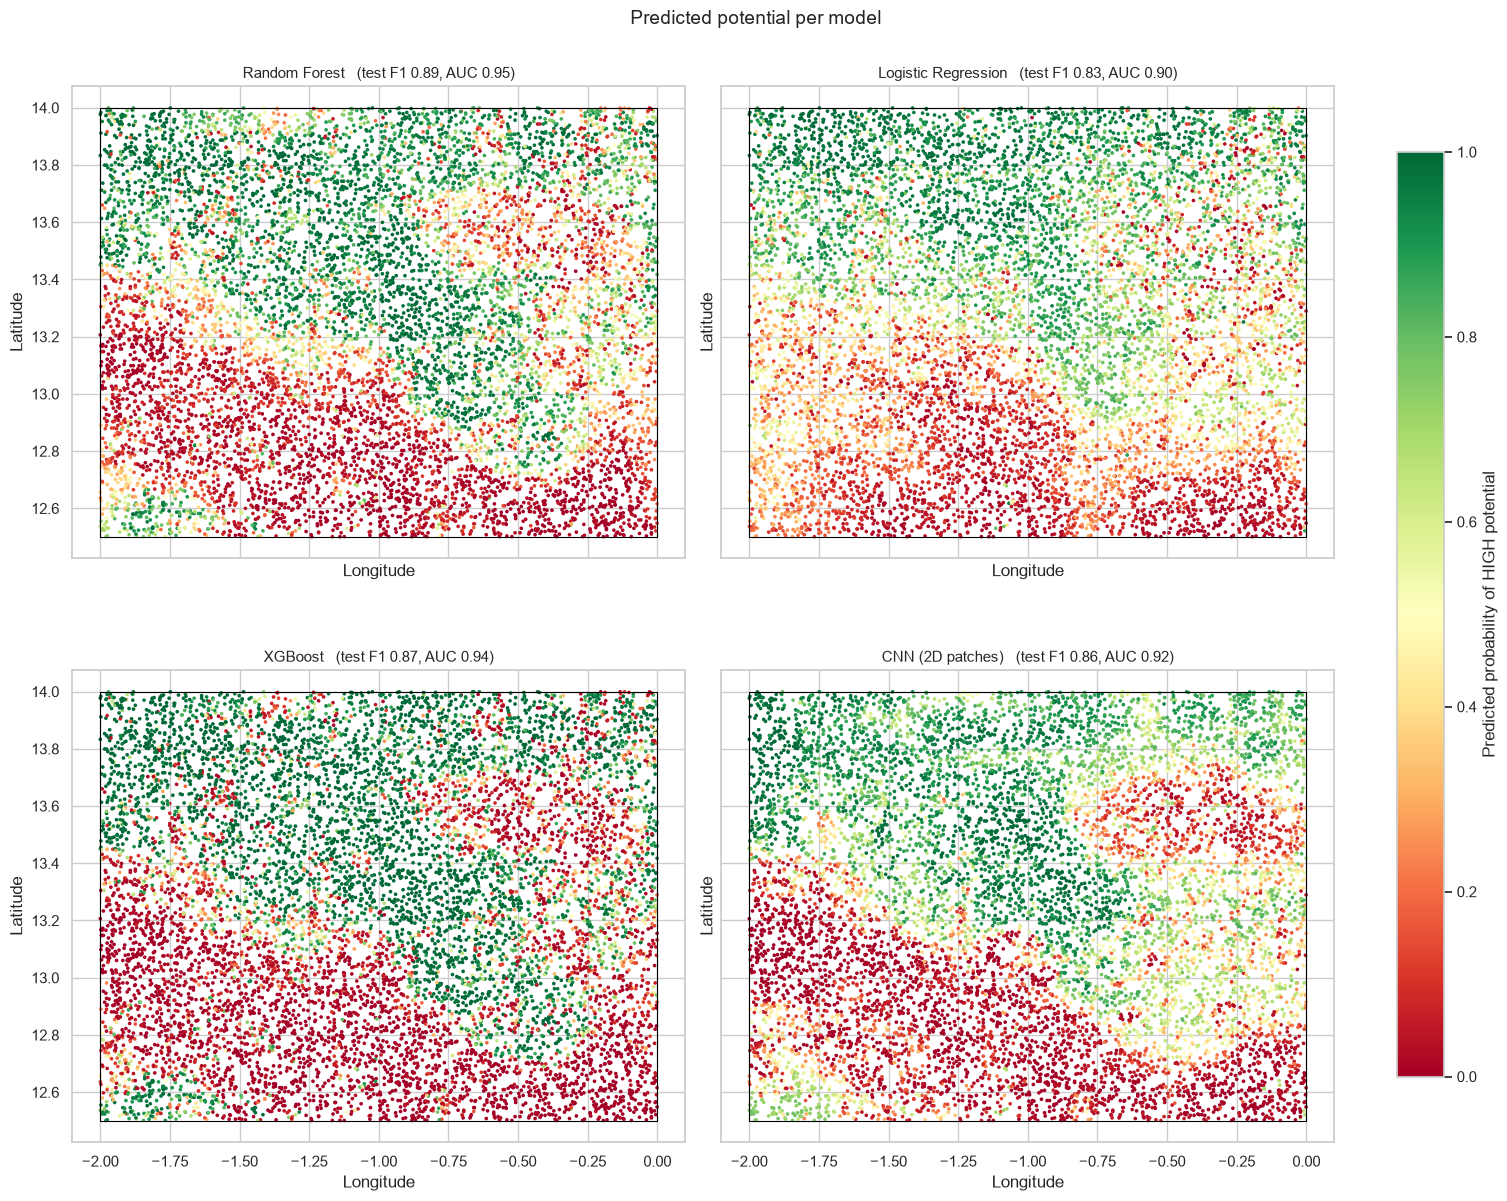

In [86]:
# ============================ FIGURE 1: ONE MAP PER MODEL ============================
n = len(score_cols); ncols = 2; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.5 * ncols, 6 * nrows), sharex=True, sharey=True, layout="constrained")
axes = np.atleast_1d(axes).ravel()
for ax, (name, col) in zip(axes, score_cols.items()):
    sc = ax.scatter(lon, lat, c=m[col].values, s=POINT_SIZE, cmap=CMAP, vmin=0, vmax=1, linewidths=0)
    style(ax, f"{name}   (test F1 {res.loc[name, 'Test F1 macro']:.2f}, AUC {res.loc[name, 'Test ROC-AUC']:.2f})")
for ax in axes[n:]:
    ax.set_visible(False)
fig.colorbar(sc, ax=list(axes[:n]), shrink=0.8, label="Predicted probability of HIGH potential")
fig.suptitle("Predicted potential per model", fontsize=14)
fig.savefig(FIGURES / "07a_maps_per_model.png", dpi=300); plt.show()

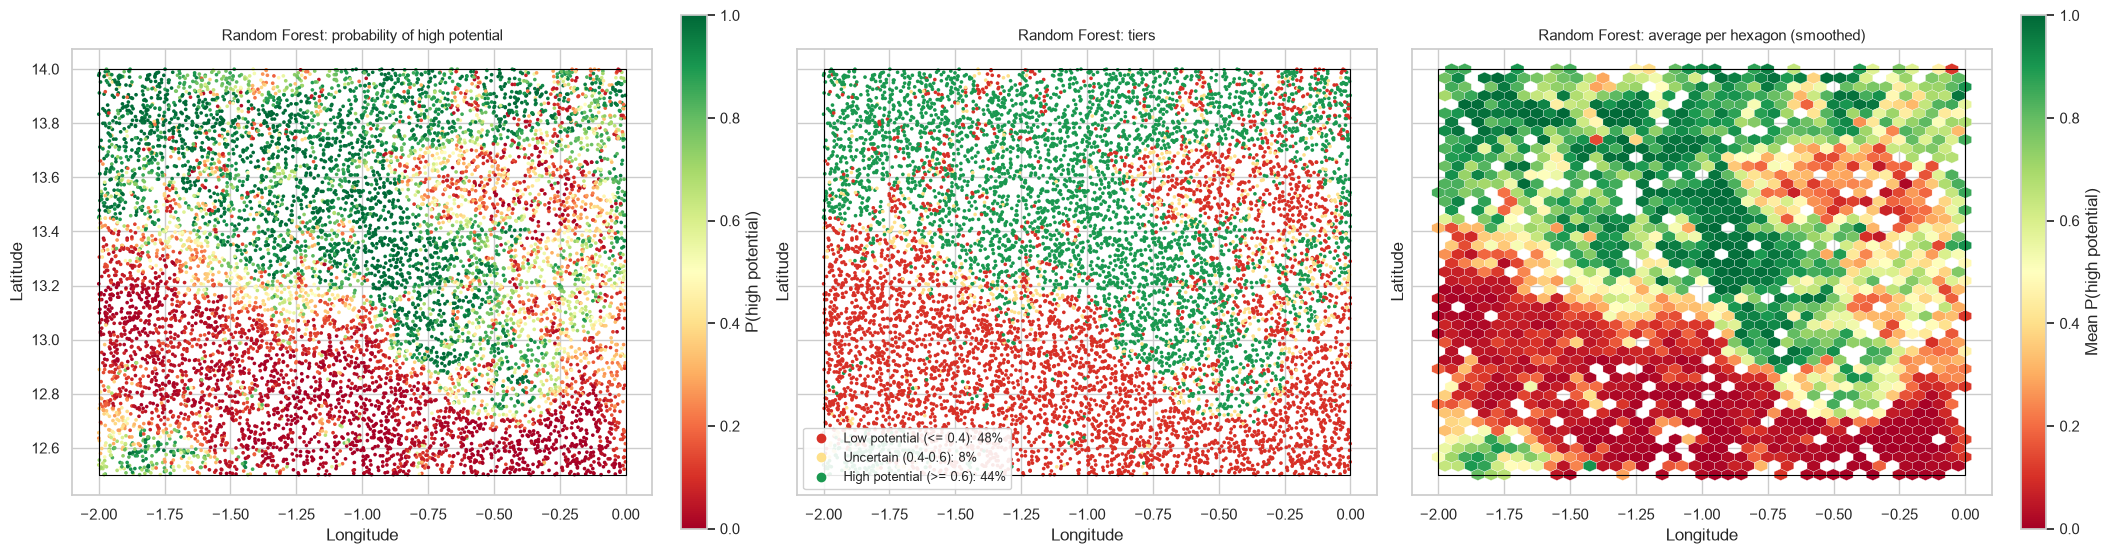

In [87]:
# ============================ FIGURE 2: BEST MODEL (continuous | tiers | smoothed) ============================
fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), sharex=True, sharey=True, layout="constrained")

sc = ax[0].scatter(lon, lat, c=best, s=POINT_SIZE, cmap=CMAP, vmin=0, vmax=1, linewidths=0)
style(ax[0], f"{best_name}: probability of high potential")
fig.colorbar(sc, ax=ax[0], shrink=0.8, label="P(high potential)")

tier = np.where(best >= HIGH_T, 2, np.where(best <= LOW_T, 0, 1))
tier_cmap = ListedColormap(["#d73027", "#fee08b", "#1a9850"])
ax[1].scatter(lon, lat, c=tier, s=POINT_SIZE, cmap=tier_cmap, vmin=0, vmax=2, linewidths=0)
style(ax[1], f"{best_name}: tiers")
labels = [f"Low potential (<= {LOW_T})", f"Uncertain ({LOW_T}-{HIGH_T})", f"High potential (>= {HIGH_T})"]
ax[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"{l}: {(tier == k).mean() * 100:.0f}%")
                      for k, (c, l) in enumerate(zip(["#d73027", "#fee08b", "#1a9850"], labels))],
             loc="lower left", fontsize=9, framealpha=0.9)

hb = ax[2].hexbin(lon, lat, C=best, gridsize=HEX_GRID, reduce_C_function=np.mean, mincnt=HEX_MIN_POINTS,
                  cmap=CMAP, vmin=0, vmax=1, linewidths=0.2, edgecolors="white")
style(ax[2], f"{best_name}: average per hexagon (smoothed)")
fig.colorbar(hb, ax=ax[2], shrink=0.8, label="Mean P(high potential)")
fig.savefig(FIGURES / "07b_map_best_model.png", dpi=300); plt.show()

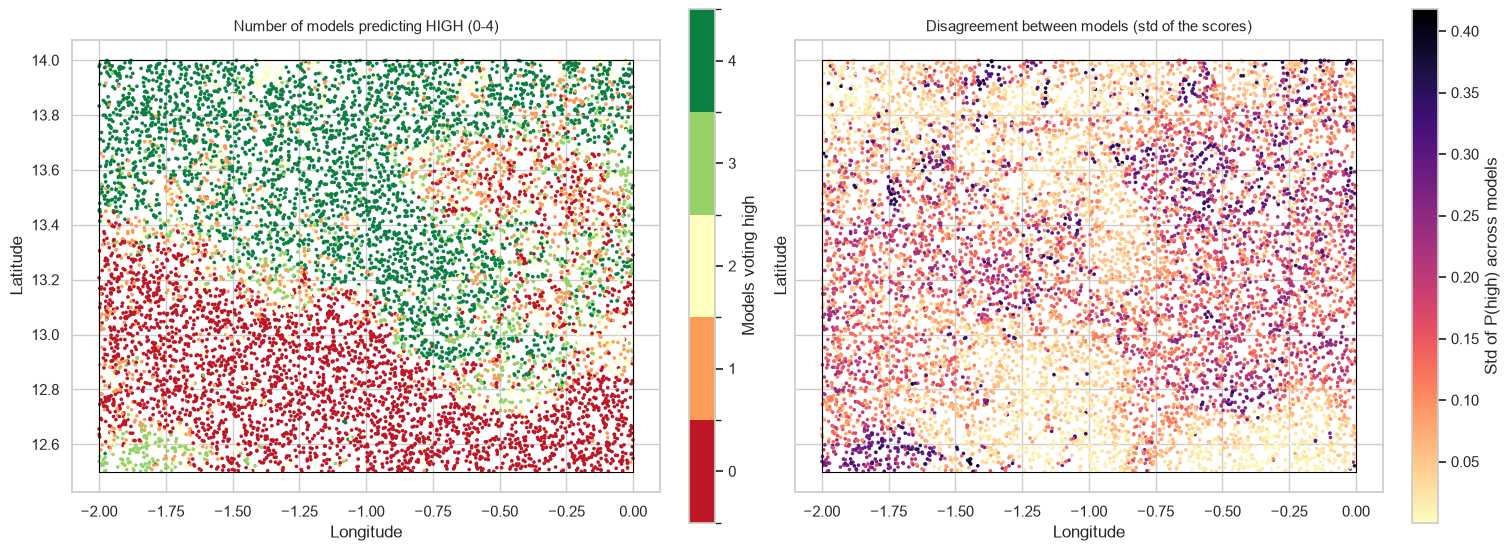


Share of points by number of models voting HIGH:
0    35.7
1    11.7
2     7.9
3     9.5
4    35.2


In [88]:
# ============================ FIGURE 3: WHERE DO THE MODELS AGREE? ============================
S_all = m[list(score_cols.values())].to_numpy()
votes = (S_all >= 0.5).sum(axis=1)                                           # how many models say "high"
spread = S_all.std(axis=1)                                                   # disagreement between the models

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
vote_cmap = ListedColormap(plt.get_cmap("RdYlGn")(np.linspace(0.05, 0.95, n + 1)))
sc = ax[0].scatter(lon, lat, c=votes, s=POINT_SIZE, cmap=vote_cmap, norm=BoundaryNorm(np.arange(-0.5, n + 1.5), n + 1), linewidths=0)
style(ax[0], f"Number of models predicting HIGH (0-{n})")
cb = fig.colorbar(sc, ax=ax[0], shrink=0.8, ticks=range(n + 1)); cb.set_label("Models voting high")
sp = ax[1].scatter(lon, lat, c=spread, s=POINT_SIZE, cmap="magma_r", linewidths=0)
style(ax[1], "Disagreement between models (std of the scores)")
fig.colorbar(sp, ax=ax[1], shrink=0.8, label="Std of P(high) across models")
fig.savefig(FIGURES / "07c_map_model_agreement.png", dpi=300); plt.show()
print("\nShare of points by number of models voting HIGH:")
print(pd.Series(votes).value_counts(normalize=True).sort_index().mul(100).round(1).rename("%").to_string())

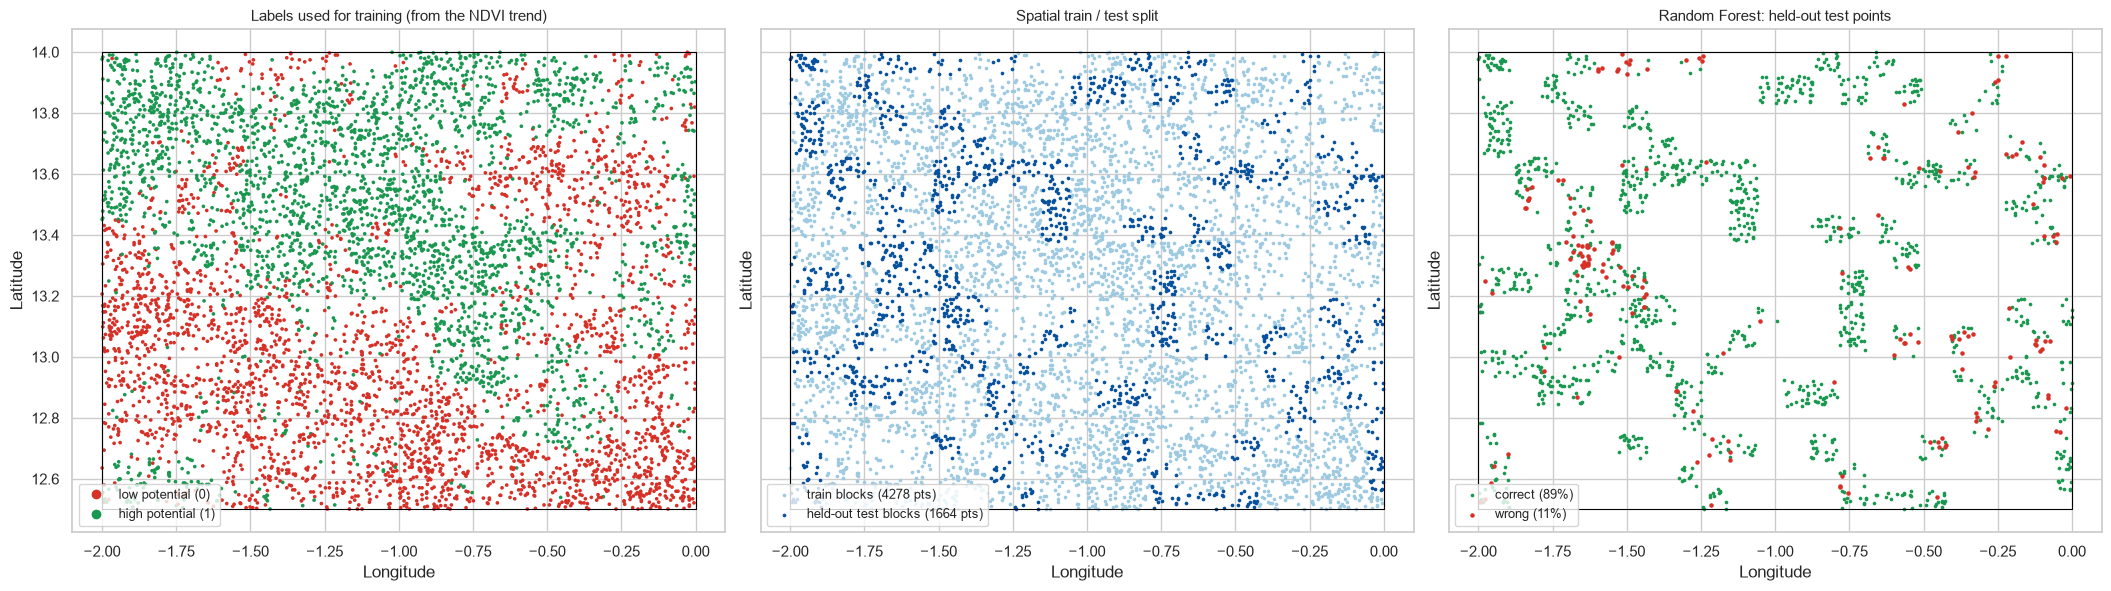

In [89]:
# ============================ FIGURE 4: LABELS, SPLIT AND ERRORS (held-out blocks) ============================
d_lon, d_lat = d.geometry.x.values, d.geometry.y.values
is_test = np.zeros(len(d), dtype=bool); is_test[te] = True
d_te = d.iloc[te]
correct = (pred[best_name] == y_te_a)

fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), sharex=True, sharey=True, layout="constrained")
ax[0].scatter(d_lon, d_lat, c=d["label"].values, s=POINT_SIZE, cmap=ListedColormap(["#d73027", "#1a9850"]), vmin=0, vmax=1, linewidths=0)
style(ax[0], "Labels used for training (from the NDVI trend)")
ax[0].legend(handles=[Line2D([], [], marker="o", ls="", color="#d73027", label="low potential (0)"),
                      Line2D([], [], marker="o", ls="", color="#1a9850", label="high potential (1)")], loc="lower left", fontsize=9)

ax[1].scatter(d_lon[~is_test], d_lat[~is_test], s=POINT_SIZE, color="#9ecae1", linewidths=0, label=f"train blocks ({(~is_test).sum()} pts)")
ax[1].scatter(d_lon[is_test], d_lat[is_test], s=POINT_SIZE, color="#08519c", linewidths=0, label=f"held-out test blocks ({is_test.sum()} pts)")
style(ax[1], "Spatial train / test split")
ax[1].legend(loc="lower left", fontsize=9)

ax[2].scatter(d_te.geometry.x.values[correct], d_te.geometry.y.values[correct], s=POINT_SIZE, color="#1a9850", linewidths=0,
              label=f"correct ({correct.mean() * 100:.0f}%)")
ax[2].scatter(d_te.geometry.x.values[~correct], d_te.geometry.y.values[~correct], s=POINT_SIZE * 1.5, color="#d73027", linewidths=0,
              label=f"wrong ({(~correct).mean() * 100:.0f}%)")
style(ax[2], f"{best_name}: held-out test points")
ax[2].legend(loc="lower left", fontsize=9)
fig.savefig(FIGURES / "07d_map_labels_split_errors.png", dpi=300); plt.show()

In [90]:
# ============================ OPTIONAL: SAVE FOR QGIS ============================
try:
    m[["geometry", "opportunity", *score_cols.values()]].to_file(DATA_PROCESSED / "predictions.gpkg", driver="GPKG")
    print(f"\nSaved predictions for QGIS: {DATA_PROCESSED / 'predictions.gpkg'}")
except Exception as e:
    print("Could not save the GeoPackage:", str(e)[:100])


Saved predictions for QGIS: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED\predictions.gpkg
